# WikiArt — recognizing a painting's style

A visitor photographs a painting. Can its style be recognized from the image?
We work with five WikiArt styles: **Baroque, Cubism, Impressionism, Pop Art and Ukiyo-e**,
with 300 paintings per style.

We first inspect the data, then train a dense network (MLP) as a baseline and examine its errors.
We compare several MLP regularization methods, train the head of a pretrained ResNet-18,
then fine-tune its last block and compare it with logistic regression.
Models are selected on validation before their final test evaluation.

Run the notebook with the settings below to review the results. The MLP's 40 epochs are already recorded;
they are rerun only when `RUN_TRAINING` is `True`. Use the **Python (WikiArt)** kernel;
installation instructions are in the [README](README.md).


## Experiment settings

The adjustable parameters are grouped here. We use two separate seeds: 0 to select WikiArt images,
and 42 for splitting and training. After a change, run the notebook again from the beginning.


In [1]:
from __future__ import annotations

import csv
import certifi
import hashlib
import io
import json
import os
import random
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image
from torch import nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Local Python uses the certificate store provided by certifi for HTTPS downloads.
_ = os.environ.setdefault("SSL_CERT_FILE", certifi.where())


In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").is_file():
    raise RuntimeError("Open the notebook from the WikiArt repository root.")

DATA_DIR = ROOT / "data/wikiart_style5"
MANIFEST_DIR = ROOT / "manifests"
MANIFEST_PATH = MANIFEST_DIR / "wikiart_style5_seed42.csv"
OUTPUT_DIR = ROOT / "outputs/mlp_baseline"
CLASSES = ["Impressionism", "Baroque", "Cubism", "Ukiyo_e", "Pop_Art"]
DOWNLOAD_DATA = False  # True to download images or resume a download
RUN_TRAINING = False  # True to rerun the MLP; otherwise reload saved results
RUN_REGULARIZATION = False  # True to rerun the five MLP experiments
RUN_RESNET_HEAD = False  # True to extract features and train the head
RUN_FINETUNING = False  # True to fine-tune layer4 from the step 6 checkpoint
RUN_LOGISTIC_REGRESSION = False  # True to rerun the C search
RUN_FINAL_EVALUATION = False  # One evaluation only: existing results are protected
RUN_TRANSFER_STUDY = False  # Run the transfer-learning comparisons across three seeds
CREATE_FRESH_TEST = False  # Create a fresh test once, excluding previously seen images
RUN_ADDITIONAL_MODELS = False  # Three additional experiments, on training and validation only
RUN_ADDITIONAL_BENCHMARK = False  # Metricr leur latence CPU sans toucher au test
SEED = 42

REPO = "huggan/wikiart"
REVISION = "d559852d2b232e0fcf195e775866964f0564f2b5"
LABEL_COLUMNS = ("style", "genre", "artist")
UNKNOWN_ARTIST = "Unknown Artist"
GB_PER_SHARD = 33.74 / 72

DOWNLOAD_CONFIG = SimpleNamespace(
    label="style", classes=CLASSES, per_class=300, size=128, no_crop=False,
    out=DATA_DIR, seed=0, strategy="fewest-shards", max_per_artist=50,
    quality=90, revision=REVISION, index_cache=None, retries=3,
    list_classes=False, dry_run=False,
)
MLP_CONFIG = SimpleNamespace(
    data=DATA_DIR, manifest=MANIFEST_PATH, output_dir=OUTPUT_DIR,
    seed=SEED, batch_size=64, epochs=40, learning_rate=1e-3,
    workers=0, device="auto",
)


## 1. Where do the images come from?

We use a subset of `huggan/wikiart` with a pinned revision to make the data reproducible.
Images are converted to RGB, center-cropped and saved at 128 × 128 pixels.
There is a cap of 50 images per named artist; `Unknown Artist` groups multiple unknown artists and is not capped.

The download covers nine shards, approximately 4.2 GB. Existing images in `data/wikiart_style5` are reused.
On a fresh clone, first set `DOWNLOAD_DATA = True`.

The download functions below are collapsed to leave more room for the analysis. They cache the label index
and can resume an interrupted download. Images remain local: the dataset license is listed as unknown.


In [3]:
def log(msg: str = "") -> None:
    print(msg, flush=True)


def open_stream(revision: str, columns=None):
    """The whole dataset as a streaming IterableDataset (optionally only some columns)."""
    from datasets import load_dataset
    kwargs = {"columns": list(columns)} if columns else {}
    return load_dataset(REPO, split="train", streaming=True, revision=revision, **kwargs)


def with_retries(fn, what: str, retries: int):
    for attempt in range(1, retries + 1):
        try:
            return fn()
        except KeyboardInterrupt:
            raise
        except Exception as e:  # network hiccups: retry with a growing pause
            if attempt == retries:
                raise
            wait = 10 * attempt
            log(f"  ! {what}: {type(e).__name__}: {str(e)[:160]} -> retry {attempt}/{retries - 1} in {wait} s")
            time.sleep(wait)


def default_index_path(revision: str) -> Path:
    return Path.home() / ".cache" / f"wikiart_label_index_{revision[:12]}.json"


def load_label_index(revision: str, cache: Path, retries: int) -> dict:
    """{'names': {label: [class names]}, 'shards': [{'style': [...], 'genre': [...], 'artist': [...]}, ...]}"""
    if cache.exists():
        index = json.loads(cache.read_text(encoding="utf-8"))
        if index.get("revision") == revision:
            log(f"Label index: {cache} ({sum(len(s['style']) for s in index['shards'])} rows, cached)")
            return index
    log("Label pass: streaming the label columns of every shard (no images, a few KB each)...")
    t0 = time.time()
    ds = with_retries(lambda: open_stream(revision, LABEL_COLUMNS), "load_dataset", retries)
    names = {k: list(ds.features[k].names) for k in LABEL_COLUMNS}
    shards = []
    for i in range(ds.n_shards):
        def read_shard(i=i):
            cols = {k: [] for k in LABEL_COLUMNS}
            for ex in ds.shard(num_shards=ds.n_shards, index=i):
                for k in LABEL_COLUMNS:
                    cols[k].append(ex[k])
            return cols
        shards.append(with_retries(read_shard, f"labels of shard {i}", retries))
        if (i + 1) % 12 == 0 or i + 1 == ds.n_shards:
            log(f"  {i + 1}/{ds.n_shards} shards indexed ({time.time() - t0:.0f} s)")
    index = {"repo": REPO, "revision": revision, "names": names, "shards": shards}
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(index), encoding="utf-8")
    log(f"Label index saved to {cache}")
    return index


In [4]:
def _norm(name: str) -> str:
    return name.lower().replace("-", "_").replace(" ", "_")


def resolve_classes(requested, names):
    lookup = {_norm(n): i for i, n in enumerate(names)}
    ids = []
    for r in requested:
        if _norm(r) not in lookup:
            sys.exit(f"Unknown class {r!r}. Valid names: {', '.join(names)}")
        if lookup[_norm(r)] not in ids:
            ids.append(lookup[_norm(r)])
    return ids


def list_classes(index: dict, label: str) -> None:
    names, shards = index["names"], index["shards"]
    unknown = names["artist"].index(UNKNOWN_ARTIST) if UNKNOWN_ARTIST in names["artist"] else -1
    count, n_shards, artists, unk = Counter(), Counter(), {}, Counter()
    for s in shards:
        seen = set()
        for c, a in zip(s[label], s["artist"]):
            count[c] += 1
            seen.add(c)
            artists.setdefault(c, set()).add(a)
            unk[c] += a == unknown
        for c in seen:
            n_shards[c] += 1
    log(f"\n{label} classes of {REPO} ({sum(count.values())} images):")
    log(f"  {'name':28s} {'images':>7s} {'shards':>7s} {'named artists':>14s} {'unknown artist':>15s}")
    for c, n in count.most_common():
        named = len(artists[c] - {unknown})
        log(f"  {names[label][c]:28s} {n:7d} {n_shards[c]:7d} {named:14d} {unk[c] / n:14.0%}")


def make_plan(index: dict, label: str, class_ids, per_class: int, max_per_artist: int, strategy: str, seed: int):
    """Choose the rows to download: returns ({shard: [rows]}, {class_id: still missing})."""
    names, shards = index["names"], index["shards"]
    unknown = names["artist"].index(UNKNOWN_ARTIST) if UNKNOWN_ARTIST in names["artist"] else -1
    rng = random.Random(seed)
    wanted = set(class_ids)
    candidates = {}
    for s, cols in enumerate(shards):
        rows = [r for r, c in enumerate(cols[label]) if c in wanted]
        rng.shuffle(rows)  # which rows of a shard are taken is random but reproducible
        candidates[s] = rows
    order = list(range(len(shards)))
    rng.shuffle(order)
    need = {c: per_class for c in class_ids}
    per_artist = Counter()

    def rows_from(s):
        """Rows that shard s would add, given what has already been planned (no side effect)."""
        need2, art2, take = dict(need), Counter(), []
        for r in candidates[s]:
            c, a = shards[s][label][r], shards[s]["artist"][r]
            if need2[c] == 0:
                continue
            if max_per_artist and a != unknown and per_artist[a] + art2[a] >= max_per_artist:
                continue
            take.append(r)
            need2[c] -= 1
            art2[a] += 1
        return take

    plan, remaining = {}, list(order)
    while any(need.values()) and remaining:
        if strategy == "fewest-shards":
            best = max(remaining, key=lambda s: len(rows_from(s)))  # ties: first in the seeded order
        else:
            best = next((s for s in remaining if rows_from(s)), remaining[0])
        take = rows_from(best)
        remaining.remove(best)
        if not take:
            break
        plan[best] = sorted(take)
        for r in take:
            need[shards[best][label][r]] -= 1
            per_artist[shards[best]["artist"][r]] += 1
    return plan, need


def print_plan(plan, need, index, label, class_ids, per_class):
    names, shards = index["names"], index["shards"]
    got = Counter(shards[s][label][r] for s, rows in plan.items() for r in rows)
    artists = Counter(shards[s]["artist"][r] for s, rows in plan.items() for r in rows)
    log(f"\nPlan: {len(plan)} shard(s) to stream (~{len(plan) * GB_PER_SHARD:.1f} GB): {sorted(plan)}")
    for c in class_ids:
        flag = "" if got[c] == per_class else f"   <- only {got[c]} available with these settings"
        log(f"  {names[label][c]:28s} {got[c]:5d} images{flag}")
    top = [(names["artist"][a], n) for a, n in artists.most_common(6)]
    log(f"  most frequent artists in the subset: {top}")
    if any(need.values()):
        log("  Warning: some classes are incomplete (try another seed, --max-per-artist 0 or fewer images).")


In [5]:
def save_image(data: bytes, dst: Path, size: int, crop: bool, quality: int):
    from PIL import Image, ImageOps
    Image.MAX_IMAGE_PIXELS = None  # some WikiArt scans are very large (trusted source)
    with Image.open(io.BytesIO(data)) as im:
        orig = im.size
        im.draft("RGB", (size, size))  # fast JPEG decoding at reduced scale (never below the requested size)
        im = im.convert("RGB")
        if crop:
            im = ImageOps.fit(im, (size, size), method=Image.Resampling.BICUBIC)
        else:
            w, h = im.size
            scale = size / min(w, h)
            im = im.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.Resampling.BICUBIC)
        tmp = dst.with_name(dst.name + ".part")
        im.save(tmp, "JPEG", quality=quality)
        tmp.replace(dst)
    return orig


def row_id(shard: int, row: int) -> str:
    return f"s{shard:02d}_r{row:04d}"


def download(plan, index, label, class_names, args, sizes):
    """Stream the planned shards and save the selected images; returns {row_id: (w, h)}."""
    from datasets import Image as HFImage
    shards = index["shards"]
    todo = {}
    for s, rows in plan.items():
        missing = [r for r in rows
                   if not (args.out / class_names[shards[s][label][r]] / f"{row_id(s, r)}.jpg").exists()]
        if missing:
            todo[s] = missing
    done_already = sum(len(r) for r in plan.values()) - sum(len(r) for r in todo.values())
    if done_already:
        log(f"Resuming: {done_already} images already on disk.")
    if not todo:
        return sizes
    log(f"Image pass: {len(todo)} shard(s) to stream. Each shard arrives in one block (~{GB_PER_SHARD:.2f} GB).")
    ds = with_retries(lambda: open_stream(args.revision), "load_dataset", args.retries)
    ds = ds.cast_column("image", HFImage(decode=False))  # raw bytes: decode only what we keep
    n_shards = ds.n_shards
    for k, (s, rows) in enumerate(sorted(todo.items()), 1):
        t0 = time.time()
        wanted = set(rows)

        def stream_shard(s=s, wanted=wanted):
            left = set(wanted)
            for r, ex in enumerate(ds.shard(num_shards=n_shards, index=s)):
                if r not in left:
                    continue
                c = shards[s][label][r]
                if ex[label] != c:  # safety net: the index must describe this exact revision
                    raise RuntimeError(f"label mismatch at shard {s}, row {r}: delete the index cache and retry")
                dst = args.out / class_names[c] / f"{row_id(s, r)}.jpg"
                sizes[row_id(s, r)] = save_image(ex["image"]["bytes"], dst, args.size, not args.no_crop, args.quality)
                left.discard(r)
                if not left:
                    break
            if left:
                raise RuntimeError(f"shard {s}: {len(left)} planned rows were not found")

        with_retries(stream_shard, f"shard {s}", args.retries)
        log(f"  shard {s:2d} ({k}/{len(todo)}): {len(rows):4d} images saved in {time.time() - t0:5.0f} s")
    return sizes


In [6]:
def write_metadata(plan, index, label, class_ids, class_names, args, sizes) -> Counter:
    names, shards = index["names"], index["shards"]
    folder_order = sorted(class_names[c] for c in class_ids)  # = ImageFolder's class_to_idx
    label_idx = {n: i for i, n in enumerate(folder_order)}
    rows_out, counts = [], Counter()
    for s in sorted(plan):
        for r in plan[s]:
            c = shards[s][label][r]
            rel = f"{class_names[c]}/{row_id(s, r)}.jpg"
            if not (args.out / rel).exists():
                continue
            w, h = sizes.get(row_id(s, r), ("", ""))
            counts[class_names[c]] += 1
            rows_out.append({
                "path": rel, "label": class_names[c], "label_idx": label_idx[class_names[c]], "id": row_id(s, r),
                "style": names["style"][shards[s]["style"][r]], "genre": names["genre"][shards[s]["genre"][r]],
                "artist": names["artist"][shards[s]["artist"][r]], "shard": s, "row": r,
                "orig_width": w, "orig_height": h})
    rows_out.sort(key=lambda d: (d["label_idx"], d["id"]))
    with open(args.out / "metadata.csv", "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows_out[0]) if rows_out else ["path"])
        wr.writeheader()
        wr.writerows(rows_out)
    info = {
        "repo": REPO, "revision": args.revision, "label": label, "classes": folder_order,
        "per_class": args.per_class, "size": args.size, "crop": not args.no_crop, "seed": args.seed,
        "strategy": args.strategy, "max_per_artist": args.max_per_artist, "shards": sorted(plan),
        "counts": {n: counts[n] for n in folder_order}, "total": sum(counts.values()),
        "notebook": "wikiart.ipynb",
        "configuration": {key: str(value) if isinstance(value, Path) else value
                          for key, value in vars(args).items()},
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    (args.out / "subset_info.json").write_text(json.dumps(info, indent=2), encoding="utf-8")
    return counts


def previous_sizes(out: Path) -> dict:
    """Original sizes recorded by a previous (interrupted) run, so that resuming keeps them."""
    meta = out / "metadata.csv"
    if not meta.exists():
        return {}
    with open(meta, newline="", encoding="utf-8") as f:
        return {d["id"]: (d.get("orig_width", ""), d.get("orig_height", "")) for d in csv.DictReader(f)}


In [7]:
def prepare_subset(args: SimpleNamespace) -> int:
    cache = args.index_cache or default_index_path(args.revision)
    index = load_label_index(args.revision, cache, args.retries)
    if args.list_classes:
        list_classes(index, args.label)
        return 0
    names = index["names"][args.label]
    class_ids = resolve_classes(args.classes, names)
    class_names = {c: names[c] for c in class_ids}
    plan, need = make_plan(index, args.label, class_ids, args.per_class, args.max_per_artist, args.strategy, args.seed)
    print_plan(plan, need, index, args.label, class_ids, args.per_class)
    if args.dry_run:
        return 0
    for c in class_ids:
        (args.out / class_names[c]).mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    sizes = download(plan, index, args.label, class_names, args, previous_sizes(args.out))
    counts = write_metadata(plan, index, args.label, class_ids, class_names, args, sizes)
    log(f"\nDone in {time.time() - t0:.0f} s: {sum(counts.values())} images in {args.out.resolve()}")
    log("  " + ", ".join(f"{n}: {k}" for n, k in sorted(counts.items())))
    log(f"  metadata: {args.out / 'metadata.csv'} | reproducibility: {args.out / 'subset_info.json'}")
    complete = all(counts[class_names[c]] >= args.per_class for c in class_ids)
    return 0 if complete else 2


In [8]:
if DOWNLOAD_DATA:
    os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "1800")
    os.environ.setdefault("HF_XET_HIGH_PERFORMANCE", "1")
    status = prepare_subset(DOWNLOAD_CONFIG)
    if status != 0:
        raise RuntimeError("The download did not produce all requested images.")
elif not (DATA_DIR / "metadata.csv").is_file() or not (DATA_DIR / "subset_info.json").is_file():
    raise FileNotFoundError(
        "Data missing: set DOWNLOAD_DATA = True in the configuration, "
        "then rerun the cells from the beginning."
    )
else:
    print("Reusing existing subset:", DATA_DIR.relative_to(ROOT))


Reusing existing subset: data/wikiart_style5


## 2. Check the data before training

We check that metadata matches the files, images open correctly, and all have the expected format.
We also compare file hashes for exact duplicates: the same image in two splits could bias evaluation.

The split is stratified by style: **70% training, 15% validation and 15% test**.
Validation selects the weights to keep. The test is used at the end, after model selection.
Inspection opens files from every split, but the MLP loads only training and validation images.


In [9]:
def inspect_and_read(data_dir: Path) -> tuple[list[dict[str, str]], dict[str, object]]:
    metadata_path = data_dir / "metadata.csv"
    subset_info_path = data_dir / "subset_info.json"
    if not metadata_path.is_file() or not subset_info_path.is_file():
        raise FileNotFoundError(f"Expected metadata.csv and subset_info.json under {data_dir}")

    rows = list(csv.DictReader(metadata_path.open(encoding="utf-8", newline="")))
    subset_info = json.loads(subset_info_path.read_text(encoding="utf-8"))
    classes = sorted({row["label"] for row in rows})
    class_to_idx = {name: index for index, name in enumerate(classes)}
    errors: dict[str, list[str]] = {
        "duplicate_metadata_paths": [],
        "missing_images": [],
        "unlisted_images": [],
        "label_or_index_mismatches": [],
        "corrupt_images": [],
        "wrong_dimensions": [],
        "wrong_modes": [],
        "wrong_formats": [],
    }

    relative_paths = [row["path"] for row in rows]
    path_counts = Counter(relative_paths)
    errors["duplicate_metadata_paths"] = sorted(path for path, count in path_counts.items() if count > 1)
    listed_paths = set(relative_paths)
    disk_paths = {
        path.relative_to(data_dir).as_posix()
        for path in data_dir.glob("*/*.jpg")
        if path.is_file()
    }
    errors["missing_images"] = sorted(listed_paths - disk_paths)
    errors["unlisted_images"] = sorted(disk_paths - listed_paths)

    class_counts = Counter(row["label"] for row in rows)
    format_counts: Counter[str] = Counter()
    dimension_counts: Counter[str] = Counter()
    mode_counts: Counter[str] = Counter()
    content_hashes: dict[str, list[str]] = defaultdict(list)

    for row in rows:
        rel_path = Path(row["path"])
        expected_idx = class_to_idx.get(row["label"])
        if (
            rel_path.is_absolute()
            or ".." in rel_path.parts
            or row["label"] not in class_to_idx
            or row["label_idx"] != str(expected_idx)
            or rel_path.parts[0] != row["label"]
        ):
            errors["label_or_index_mismatches"].append(row["path"])

        image_path = data_dir / rel_path
        if not image_path.is_file():
            continue
        try:
            with Image.open(image_path) as image:
                image.load()
                format_name = image.format or "unknown"
                size = image.size
                mode = image.mode
            format_counts[format_name] += 1
            dimension_counts[f"{size[0]}x{size[1]}"] += 1
            mode_counts[mode] += 1
            if size != (128, 128):
                errors["wrong_dimensions"].append(row["path"])
            if mode != "RGB":
                errors["wrong_modes"].append(row["path"])
            if format_name != "JPEG":
                errors["wrong_formats"].append(row["path"])
            content_hashes[hashlib.sha256(image_path.read_bytes()).hexdigest()].append(row["path"])
        except Exception as error:  # Keep the offending path in the quality report.
            errors["corrupt_images"].append(f"{row['path']}: {type(error).__name__}: {error}")

    duplicate_content = [paths for paths in content_hashes.values() if len(paths) > 1]
    artist_counts = Counter(row.get("artist", UNKNOWN_ARTIST) for row in rows)
    report: dict[str, object] = {
        "dataset": {
            "repo": subset_info["repo"],
            "revision": subset_info["revision"],
            "label": subset_info["label"],
            "classes": classes,
            "class_to_idx": class_to_idx,
            "metadata_rows": len(rows),
            "image_files": len(disk_paths),
            "class_counts": dict(sorted(class_counts.items())),
        },
        "image_integrity": {
            "format_counts": dict(sorted(format_counts.items())),
            "dimension_counts": dict(sorted(dimension_counts.items())),
            "mode_counts": dict(sorted(mode_counts.items())),
            "exact_duplicate_groups": len(duplicate_content),
            "exact_duplicate_images": sum(len(paths) for paths in duplicate_content),
            "errors": errors,
        },
        "artist_coverage": {
            "unknown_artist_images": artist_counts.get(UNKNOWN_ARTIST, 0),
            "unknown_artist_fraction": artist_counts.get(UNKNOWN_ARTIST, 0) / max(1, len(rows)),
            "named_artist_count": len([artist for artist in artist_counts if artist != UNKNOWN_ARTIST]),
        },
    }

    class_counts_match = all(class_counts[name] == subset_info["per_class"] for name in classes)
    report["image_integrity"]["class_counts_match_subset_plan"] = class_counts_match
    error_count = sum(len(values) for values in errors.values())
    if error_count or not class_counts_match or len(disk_paths) != len(rows):
        raise ValueError(
            f"Dataset inspection found {error_count} file/label errors; "
            f"class_counts_match_subset_plan={class_counts_match}."
        )
    return rows, report


In [10]:
def stratified_split(rows: list[dict[str, str]], seed: int) -> list[dict[str, object]]:
    classes = sorted({row["label"] for row in rows})
    class_to_idx = {name: index for index, name in enumerate(classes)}
    by_class: dict[str, list[dict[str, str]]] = defaultdict(list)
    for row in rows:
        by_class[row["label"]].append(row)

    rng = random.Random(seed)
    manifest: list[dict[str, object]] = []
    for label in classes:
        members = sorted(by_class[label], key=lambda row: row["path"])
        rng.shuffle(members)
        n_train = int(len(members) * 0.70)
        n_validation = int(len(members) * 0.15)
        boundaries = (
            ("train", members[:n_train]),
            ("validation", members[n_train:n_train + n_validation]),
            ("test", members[n_train + n_validation:]),
        )
        for split_name, selected in boundaries:
            for row in selected:
                manifest.append({
                    "relative_path": row["path"],
                    "label": label,
                    "label_idx": class_to_idx[label],
                    "split": split_name,
                    "seed": seed,
                    "artist": row.get("artist", UNKNOWN_ARTIST),
                })
    return sorted(manifest, key=lambda row: (row["label_idx"], row["split"], row["relative_path"]))


In [11]:
def prepare_data(args: SimpleNamespace) -> None:
    data_dir = args.data.expanduser().resolve()
    output_dir = args.output_dir.expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)

    rows, report = inspect_and_read(data_dir)
    manifest = stratified_split(rows, args.seed)
    split_counts: dict[str, dict[str, int]] = {}
    for split_name in ("train", "validation", "test"):
        split_counts[split_name] = dict(sorted(Counter(
            str(row["label"]) for row in manifest if row["split"] == split_name
        ).items()))

    artist_splits: dict[str, set[str]] = defaultdict(set)
    for row in manifest:
        artist = str(row["artist"])
        if artist != UNKNOWN_ARTIST:
            artist_splits[artist].add(str(row["split"]))
    report["split"] = {
        "seed": args.seed,
        "fractions": {"train": 0.70, "validation": 0.15, "test": 0.15},
        "row_count": len(manifest),
        "counts": {split: sum(counts.values()) for split, counts in split_counts.items()},
        "class_counts": split_counts,
        "named_artists_present_in_multiple_splits": sum(len(splits) > 1 for splits in artist_splits.values()),
        "note": "Stratified by class. Artist grouping is not applied; Unknown Artist is a catch-all label.",
    }

    stem = f"{data_dir.name}_seed{args.seed}"
    manifest_path = output_dir / f"{stem}.csv"
    report_path = output_dir / f"{stem}_inspection.json"
    fieldnames = ("relative_path", "label", "label_idx", "split", "seed", "artist")
    with manifest_path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(manifest)
    report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

    print(f"Inspected: {len(rows)} images, {len(report['dataset']['classes'])} classes.")
    print("Formats :", report["image_integrity"]["format_counts"])
    print("Dimensions :", report["image_integrity"]["dimension_counts"])
    print("Modes :", report["image_integrity"]["mode_counts"])
    print("Exact duplicates:", report["image_integrity"]["exact_duplicate_groups"])
    print("Split:", report["split"]["counts"])
    print("Par classe :", report["split"]["class_counts"])
    print("Manifeste :", manifest_path)
    print("Rapport :", report_path)


In [12]:
prepare_data(SimpleNamespace(data=DATA_DIR, output_dir=MANIFEST_DIR, seed=SEED))
inspection = json.loads(
    (MANIFEST_DIR / f"{DATA_DIR.name}_seed{SEED}_inspection.json").read_text(encoding="utf-8")
)

# Counts by style and split, from the saved report.
counts = pd.DataFrame(inspection["split"]["class_counts"])
counts.index.name = "Style"
counts.rename(columns={"train": "Training", "validation": "Validation", "test": "Test"})


Inspected: 1500 images, 5 classes.
Formats : {'JPEG': 1500}
Dimensions : {'128x128': 1500}
Modes : {'RGB': 1500}
Exact duplicates: 0
Split: {'train': 1050, 'validation': 225, 'test': 225}
Par classe : {'train': {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}, 'validation': {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}, 'test': {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}}
Manifeste : /Users/20016359/Desktop/Master II Mines/Deep-Learning-Wikiart/manifests/wikiart_style5_seed42.csv
Rapport : /Users/20016359/Desktop/Master II Mines/Deep-Learning-Wikiart/manifests/wikiart_style5_seed42_inspection.json


,Training,Validation,Test
Style,,,
Baroque,210,45,45
Cubism,210,45,45
Impressionism,210,45,45
Pop_Art,210,45,45
Ukiyo_e,210,45,45


### What about artists?

Two paintings by the same artist can share details recognized by the model.
A style-stratified split alone does not guarantee that it learns only style.
We examine how many artists are identified and how many appear in multiple splits.


In [13]:
coverage = inspection["artist_coverage"]
print(f"Unknown artist: {coverage['unknown_artist_images']} images ({coverage['unknown_artist_fraction']:.1%})")
print("Named artists:", coverage["named_artist_count"])
print("Named artists in multiple splits:",
      inspection["split"]["named_artists_present_in_multiple_splits"])


Unknown artist: 1402 images (93.5%)
Named artists: 15
Named artists in multiple splits: 7


**Key findings.** All 1,500 files are 128 × 128 RGB JPEGs, with no exact duplicates.
Each style has 210 training, 45 validation and 45 test images.

However, 93.5% of images have the `Unknown Artist` label and seven named artists appear in multiple splits.
Artist separation therefore cannot be verified for most paintings. This limits the interpretation of the scores.


## 3. A first model: the MLP

For this first experiment, images are resized to 64 × 64 pixels and values scaled to [-1, 1].
With three color channels, this gives **3 × 64 × 64 = 12,288 values per image**.
The MLP receives a flattened image: it does not directly exploit neighboring pixels.

The five classes are balanced, so uniform random prediction would have an expected accuracy of 20%.
This provides a reference for interpreting results.


In [14]:
INPUT_SIZE = 64
NORMALIZE_MEAN = (0.5, 0.5, 0.5)
NORMALIZE_STD = (0.5, 0.5, 0.5)

def choose_device(requested: str) -> torch.device:
    if requested != "auto":
        device = torch.device(requested)
        if device.type == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA was requested but is unavailable.")
        if device.type == "mps" and not torch.backends.mps.is_available():
            raise RuntimeError("MPS was requested but is unavailable.")
        return device
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


In [15]:
class ManifestImageDataset(Dataset[tuple[torch.Tensor, torch.Tensor]]):
    def __init__(
        self,
        data_dir: Path,
        records: list[dict[str, str]],
        transform: transforms.Compose,
    ) -> None:
        self.data_dir = data_dir
        self.records = records
        self.transform = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        record = self.records[index]
        image_path = (self.data_dir / record["relative_path"]).resolve()
        if not image_path.is_relative_to(self.data_dir):
            raise ValueError(f"Manifest image path escapes the data directory: {record['relative_path']}")
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            tensor = self.transform(image)
        label = torch.tensor(int(record["label_idx"]), dtype=torch.long)
        return tensor, label


In [16]:
def read_training_rows(
    data_dir: Path,
    manifest_path: Path,
    seed: int,
    workers: int,
    batch_size: int,
) -> tuple[dict[str, DataLoader], list[str], dict[str, dict[str, int]], int]:
    train_records: list[dict[str, str]] = []
    validation_records: list[dict[str, str]] = []
    split_counts: dict[str, Counter[str]] = {
        "train": Counter(),
        "validation": Counter(),
        "test": Counter(),
    }
    class_map: dict[int, str] = {}
    with manifest_path.open(encoding="utf-8", newline="") as stream:
        reader = csv.DictReader(stream)
        required = {"relative_path", "label", "label_idx", "split", "seed"}
        if not reader.fieldnames or not required.issubset(reader.fieldnames):
            raise ValueError(f"Manifest must contain columns: {sorted(required)}")
        for row in reader:
            split_name = row["split"]
            if split_name not in split_counts:
                raise ValueError(f"Unexpected split in manifest: {split_name}")
            index = int(row["label_idx"])
            prior = class_map.setdefault(index, row["label"])
            if prior != row["label"]:
                raise ValueError(f"label_idx {index} maps to both {prior!r} and {row['label']!r}")
            split_counts[split_name][row["label"]] += 1
            if split_name in ("train", "validation"):
                if int(row["seed"]) != seed:
                    raise ValueError(
                        f"Manifest seed {row['seed']} does not match requested seed {seed}."
                    )
                train_records.append(row) if split_name == "train" else validation_records.append(row)

    class_names = [class_map[index] for index in sorted(class_map)]
    if sorted(class_map) != list(range(len(class_names))):
        raise ValueError("Manifest label indices must be contiguous starting at zero.")
    if not train_records or not validation_records:
        raise ValueError("The manifest must contain non-empty train and validation splits.")
    if not split_counts["test"]:
        raise ValueError("The manifest has no test split.")

    transform = transforms.Compose([
        transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ])
    train_dataset = ManifestImageDataset(data_dir, train_records, transform)
    validation_dataset = ManifestImageDataset(data_dir, validation_records, transform)
    generator = torch.Generator().manual_seed(seed)
    loaders = {
        "train": DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=workers,
            generator=generator,
        ),
        "validation": DataLoader(
            validation_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=workers,
        ),
    }
    return (
        loaders,
        class_names,
        {split: dict(counts) for split, counts in split_counts.items()},
        len(train_records),
    )


### The network

We use two hidden layers with 256 and 128 neurons, each followed by ReLU.
The final layer gives five scores, one per style. The model has no softmax:
`CrossEntropyLoss` takes these scores, the logits, directly.


In [17]:
class ArtworkMLP(nn.Module):
    """Two hidden layers; the output contains one logit per style."""
    def __init__(self, num_classes: int) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * INPUT_SIZE * INPUT_SIZE, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.layers(images)


### The training loop

For each batch, we reset gradients, calculate the loss and update weights with Adam.
For validation, we use evaluation mode and disable gradient computation.
Losses are weighted by image count because the final batch may be smaller.


In [18]:
def train_epoch(
    model: ArtworkMLP,
    loader: DataLoader,
    loss_function: nn.CrossEntropyLoss,
    optimizer: Adam,
    device: torch.device,
) -> tuple[float, float]:
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device, dtype=torch.long)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        count = labels.size(0)
        total_loss += loss.item() * count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += count
    return total_loss / total, correct / total


In [19]:
@torch.inference_mode()
def validate_epoch(
    model: ArtworkMLP,
    loader: DataLoader,
    loss_function: nn.CrossEntropyLoss,
    device: torch.device,
) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device, dtype=torch.long)
        logits = model(images)
        loss = loss_function(logits, labels)
        count = labels.size(0)
        total_loss += loss.item() * count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += count
    return total_loss / total, correct / total


def write_history(history: list[dict[str, Any]], path: Path) -> None:
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)


## 4. Train and keep the best epoch

We use 40 epochs, batches of 64 and a learning rate of 0.001.
After each epoch, we measure validation loss and accuracy. We keep the weights with the highest
validation accuracy, breaking ties with the lowest loss.

`RUN_TRAINING = False` goes directly to the saved experiment's curves.
To preserve this experiment before starting another, change `output_dir` in `MLP_CONFIG`.


In [20]:
args = MLP_CONFIG
data_dir = args.data.expanduser().resolve()
manifest_path = args.manifest.expanduser().resolve()
output_dir = args.output_dir.expanduser().resolve()
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir = output_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

set_seed(args.seed)
device = choose_device(args.device)
loaders, class_names, split_counts, train_count = read_training_rows(
    data_dir, manifest_path, args.seed, args.workers, args.batch_size
)
print(f"Device: {device}")
print("Styles :", class_names)
print(f"Images loaded: {train_count} training, {sum(split_counts['validation'].values())} validation")

model = ArtworkMLP(num_classes=len(class_names)).to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=args.learning_rate)
history: list[dict[str, Any]] = []
best_accuracy = -1.0
best_loss = float("inf")
best_state: dict[str, torch.Tensor] | None = None
best_epoch = 0
best_train_accuracy = 0.0
start_time = time.perf_counter()

print(model)
print("Trainable parameters :", sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: mps
Styles : ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
Images loaded: 1050 training, 225 validation


ArtworkMLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=5, bias=True)
  )
)
Trainable parameters : 3179525


In [21]:
if RUN_TRAINING:
    for epoch in range(1, args.epochs + 1):
        train_loss, train_accuracy = train_epoch(
            model, loaders["train"], loss_function, optimizer, device
        )
        validation_loss, validation_accuracy = validate_epoch(
            model, loaders["validation"], loss_function, device
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "learning_rate": args.learning_rate,
        })
        print(
            f"epoch {epoch:02d}/{args.epochs}: "
            f"train loss={train_loss:.4f} acc={train_accuracy:.3f} | "
            f"val loss={validation_loss:.4f} acc={validation_accuracy:.3f}",
            flush=True,
        )

        if (
            validation_accuracy > best_accuracy
            or (validation_accuracy == best_accuracy and validation_loss < best_loss)
        ):
            best_accuracy = validation_accuracy
            best_loss = validation_loss
            best_epoch = epoch
            best_train_accuracy = train_accuracy
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }
else:
    print("Training disabled: loading saved results in the next section.")


Training disabled: loading saved results in the next section.


We save the selected weights, per-epoch history and experiment settings.
The CSV and JSON summary allow results to be reviewed without retraining; weights are excluded from Git.


In [22]:
if RUN_TRAINING:
    if best_state is None:
        raise RuntimeError("Training produced no validation checkpoint.")

    checkpoint_path = checkpoint_dir / "mlp_baseline_best.pt"
    torch.save({
        "model_state_dict": best_state,
        "class_names": class_names,
        "input_size": INPUT_SIZE,
        "normalization_mean": NORMALIZE_MEAN,
        "normalization_std": NORMALIZE_STD,
        "best_epoch": best_epoch,
        "seed": args.seed,
    }, checkpoint_path)
    model.load_state_dict(best_state)
    history_path = output_dir / "training_history.csv"
    write_history(history, history_path)

    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    summary = {
        "model": "Dense MLP baseline",
        "architecture": f"{3 * INPUT_SIZE * INPUT_SIZE} -> 256 -> 128 -> {len(class_names)} with ReLU; raw logits",
        "loss": "CrossEntropyLoss",
        "optimizer": "Adam",
        "learning_rate": args.learning_rate,
        "batch_size": args.batch_size,
        "epochs_run": args.epochs,
        "best_checkpoint_selected_by": "maximum validation accuracy, then minimum validation loss",
        "best_epoch": best_epoch,
        "best_validation_accuracy": best_accuracy,
        "best_validation_loss": best_loss,
        "train_accuracy_at_best_epoch": best_train_accuracy,
        "train_validation_accuracy_gap": best_train_accuracy - best_accuracy,
        "parameter_count": parameter_count,
        "seed": args.seed,
        "device": str(device),
        "input": f"RGB {INPUT_SIZE}x{INPUT_SIZE}, normalized to [-1, 1]",
        "split_counts_from_manifest": split_counts,
        "test_evaluated": False,
        "training_seconds": time.perf_counter() - start_time,
        "checkpoint": str(checkpoint_path.relative_to(Path.cwd())),
        "history": str(history_path.relative_to(Path.cwd())),
    }
    (output_dir / "validation_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n", encoding="utf-8"
    )
    print(
        f"Best validation checkpoint: epoch {best_epoch}, "
        f"accuracy={best_accuracy:.3f}, loss={best_loss:.4f}",
        flush=True,
    )
    print(f"Test set not evaluated. Artifacts: {output_dir}", flush=True)


## 5. What do the results show?

We reload the experiment saved in the output directory. Training values were measured during weight updates;
validation values were measured at the end of each epoch, so they were not calculated at exactly the same time.


In [23]:
history_path = output_dir / "training_history.csv"
summary_path = output_dir / "validation_summary.json"
if not history_path.is_file() or not summary_path.is_file():
    raise FileNotFoundError("No results found: set RUN_TRAINING = True and rerun the notebook.")

history = pd.read_csv(history_path)
summary = json.loads(summary_path.read_text(encoding="utf-8"))

print(f"Saved experiment: {summary['epochs_run']} epochs on {summary['device']}")
print(f"Selected checkpoint: epoch {summary['best_epoch']}")
pd.DataFrame({
    "Metric": ["Training accuracy at this epoch", "Validation accuracy", "Training / validation gap"],
    "Value": [f"{summary['train_accuracy_at_best_epoch']:.1%}",
               f"{summary['best_validation_accuracy']:.1%}",
               f"{100 * summary['train_validation_accuracy_gap']:.1f} points"],
}).set_index("Metric")


Saved experiment: 40 epochs on mps
Selected checkpoint: epoch 28


,Value
Metric,
Training accuracy at this epoch,98.6%
Validation accuracy,39.6%
Training / validation gap,59.0 points


### Learning curves

We examine both curves together: if training keeps improving while validation stagnates or deteriorates,
the network is memorizing training examples without improving generalization.


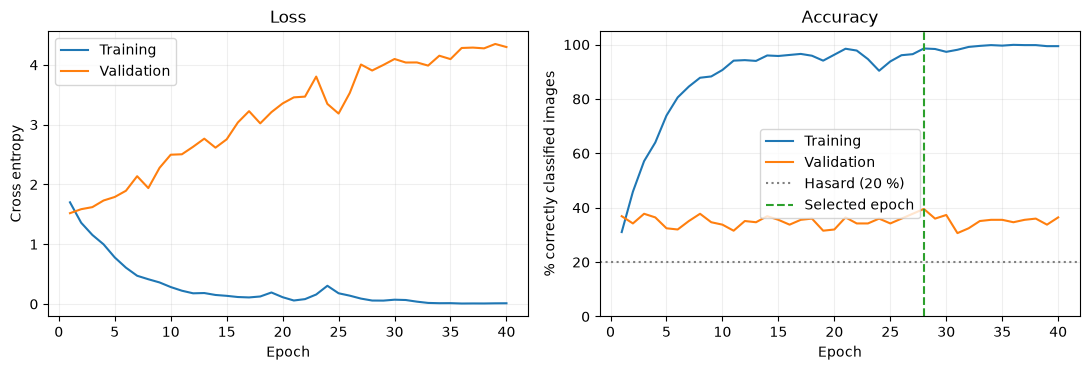

In [24]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))

for split, label in (("train", "Training"), ("validation", "Validation")):
    ax_loss.plot(history["epoch"], history[f"{split}_loss"], label=label)
    ax_acc.plot(history["epoch"], 100 * history[f"{split}_accuracy"], label=label)

ax_loss.set(title="Loss", xlabel="Epoch", ylabel="Cross entropy")
ax_acc.set(title="Accuracy", xlabel="Epoch", ylabel="% correctly classified images", ylim=(0, 105))
ax_acc.axhline(20, color="gray", linestyle=":", label="Hasard (20 %)")
ax_acc.axvline(summary["best_epoch"], color="tab:green", linestyle="--", label="Selected epoch")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


### Observations from the first experiment

The MLP reaches **39.6% validation accuracy at epoch 28**, compared with **98.6% training accuracy**.
The gap is approximately **59 percentage points**. The score exceeds the 20% expected by chance,
but remains far below the training result.

Training loss falls almost to zero while validation loss rises; validation accuracy stays broadly flat.
Both observations indicate substantial overfitting. Keeping the best epoch avoids selecting the final weights,
but does not solve the problem.

This result uses one seed. We have not yet measured variability or examined which styles are most confused,
so we cannot attribute errors to a particular style or conclude that a small gain is significant.


## 6. Step 5 — reduce MLP overfitting

The previous baseline learns the training set almost perfectly but generalizes poorly.
We try to reduce the gap by changing one thing at a time: dropout of 0.3 in both hidden layers,
weight decay of 0.0001, and then both together. A fifth experiment uses the unregularized MLP
with early stopping after eight epochs without validation checkpoint improvement.

We keep the same images, split, seed, Adam optimizer and maximum of 40 epochs.
We also rerun a baseline in the current environment: library versions can differ from the first experiment,
so its 39.6% score alone cannot isolate the effects of these changes.

Dropout is disabled during evaluation. To compare gaps fairly, training is also measured in evaluation mode
each epoch; measurements during updates are kept separately.


In [25]:
REGULARIZATION_DIR = ROOT / "outputs/mlp_regularization"
MLP_EXPERIMENTS = [
    {"name": "reference", "dropout": 0.0, "weight_decay": 0.0, "patience": None},
    {"name": "dropout", "dropout": 0.3, "weight_decay": 0.0, "patience": None},
    {"name": "weight_decay", "dropout": 0.0, "weight_decay": 1e-4, "patience": None},
    {"name": "dropout_weight_decay", "dropout": 0.3, "weight_decay": 1e-4, "patience": None},
    {"name": "early_stopping", "dropout": 0.0, "weight_decay": 0.0, "patience": 8},
]

class RegularizedMLP(nn.Module):
    def __init__(self, num_classes, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * INPUT_SIZE * INPUT_SIZE, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        return self.layers(images)

pd.DataFrame(MLP_EXPERIMENTS).set_index("name")


,dropout,weight_decay,patience
name,,,
reference,0.0,0.0000,NaN
dropout,0.3,0.0000,NaN
weight_decay,0.0,0.0001,NaN
dropout_weight_decay,0.3,0.0001,NaN
early_stopping,0.0,0.0000,8.0


### A common protocol

A checkpoint improves when validation accuracy increases, or when loss decreases at equal accuracy.
The same criterion resets the early-stopping counter. Other runs continue for 40 epochs.
We save the history, selected weights and validation confusion matrix for each run.
No test image loader is created.


In [26]:
def checkpoint_improves(accuracy, loss, best_accuracy, best_loss):
    return accuracy > best_accuracy or (accuracy == best_accuracy and loss < best_loss)


def fit_experiment(model, experiment_loaders, *, epochs, learning_rate, weight_decay,
                   patience, seed, experiment_device):
    loss_function = nn.CrossEntropyLoss()
    optimizer = Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=learning_rate, weight_decay=weight_decay,
    )
    # This loader does not shuffle images or consume the training batch generator.
    train_eval = DataLoader(experiment_loaders["train"].dataset, batch_size=64, shuffle=False)
    records, best_state = [], None
    best_accuracy, best_loss, best_epoch, stale_epochs = -1.0, float("inf"), 0, 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        online_loss, online_accuracy = train_epoch(
            model, experiment_loaders["train"], loss_function, optimizer, experiment_device
        )
        train_loss, train_accuracy = validate_epoch(model, train_eval, loss_function, experiment_device)
        val_loss, val_accuracy = validate_epoch(
            model, experiment_loaders["validation"], loss_function, experiment_device
        )
        records.append({
            "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
            "validation_loss": val_loss, "validation_accuracy": val_accuracy,
            "online_train_loss": online_loss, "online_train_accuracy": online_accuracy,
            "learning_rate": learning_rate,
        })
        if checkpoint_improves(val_accuracy, val_loss, best_accuracy, best_loss):
            best_accuracy, best_loss, best_epoch, stale_epochs = val_accuracy, val_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale_epochs += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:02d} : train {train_accuracy:.1%}, validation {val_accuracy:.1%}", flush=True)
        if patience is not None and stale_epochs >= patience:
            print(f"  stopped at epoch {epoch} : {patience} epochs without improvement", flush=True)
            break

    model.load_state_dict(best_state)
    return records, {
        "epochs_run": len(records), "best_epoch": best_epoch,
        "best_validation_accuracy": best_accuracy, "best_validation_loss": best_loss,
        "train_accuracy_at_best_epoch": records[best_epoch - 1]["train_accuracy"],
        "train_validation_accuracy_gap": records[best_epoch - 1]["train_accuracy"] - best_accuracy,
        "stopped_early": len(records) < epochs, "training_seconds": time.perf_counter() - started,
    }


@torch.inference_mode()
def validation_confusion(model, loader, num_classes, experiment_device):
    model.eval()
    matrix = torch.zeros((num_classes, num_classes), dtype=torch.long)
    for images, labels in loader:
        predictions = model(images.to(experiment_device)).argmax(dim=1).cpu()
        matrix += torch.bincount(labels * num_classes + predictions, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return matrix


def save_experiment(model, records, result, folder, configuration, classes, matrix, extra_checkpoint=None):
    import torchvision
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = folder / "checkpoints"
    checkpoint_dir.mkdir(exist_ok=True)
    checkpoint = checkpoint_dir / "best.pt"
    torch.save({
        "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "class_names": classes, "config": configuration,
        "best_epoch": result["best_epoch"], **(extra_checkpoint or {}),
    }, checkpoint)
    pd.DataFrame(records).to_csv(folder / "training_history.csv", index=False)
    pd.DataFrame(matrix.tolist(), index=classes, columns=classes).rename_axis("true_style").to_csv(
        folder / "validation_confusion.csv"
    )
    result.update({
        "config": configuration, "class_names": classes, "test_evaluated": False,
        "checkpoint": checkpoint.relative_to(ROOT).as_posix(),
        "manifest": MANIFEST_PATH.relative_to(ROOT).as_posix(),
        "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
        "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "python": sys.version.split()[0]},
    })
    (folder / "validation_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def run_mlp_experiments():
    experiment_device = choose_device(MLP_CONFIG.device)
    for settings in MLP_EXPERIMENTS:
        print("Experiment :", settings["name"], flush=True)
        set_seed(SEED)
        experiment_loaders, classes, _, _ = read_training_rows(DATA_DIR, MANIFEST_PATH, SEED, 0, 64)
        model = RegularizedMLP(len(classes), settings["dropout"]).to(experiment_device)
        records, result = fit_experiment(
            model, experiment_loaders, epochs=40, learning_rate=1e-3,
            weight_decay=settings["weight_decay"], patience=settings["patience"],
            seed=SEED, experiment_device=experiment_device,
        )
        result.update({"model": "Regularized MLP", "device": str(experiment_device),
                       "parameter_count": sum(p.numel() for p in model.parameters())})
        matrix = validation_confusion(model, experiment_loaders["validation"], len(classes), experiment_device)
        configuration = {**settings, "seed": SEED, "epochs": 40, "learning_rate": 1e-3,
                         "batch_size": 64, "input_size": 64, "normalization_mean": NORMALIZE_MEAN,
                         "normalization_std": NORMALIZE_STD,
                         "checkpoint_selection": "validation accuracy, then validation loss",
                         "train_metrics": "eval mode after each epoch"}
        save_experiment(model, records, result, REGULARIZATION_DIR / settings["name"], configuration, classes, matrix)
        print(f"  best checkpoint: {result['best_validation_accuracy']:.1%} at epoch {result['best_epoch']}", flush=True)

if RUN_REGULARIZATION:
    run_mlp_experiments()


In [27]:
mlp_results = {}
for settings in MLP_EXPERIMENTS:
    result_path = REGULARIZATION_DIR / settings["name"] / "validation_summary.json"
    if not result_path.is_file():
        raise FileNotFoundError("Regularization results missing: set RUN_REGULARIZATION = True.")
    mlp_results[settings["name"]] = json.loads(result_path.read_text(encoding="utf-8"))

mlp_comparison = pd.DataFrame([
    {"Experiment": name, "Epochs": result["epochs_run"], "Best epoch": result["best_epoch"],
     "Train (%)": 100 * result["train_accuracy_at_best_epoch"],
     "Validation (%)": 100 * result["best_validation_accuracy"],
     "Gap (points)": 100 * result["train_validation_accuracy_gap"],
     "Validation loss": result["best_validation_loss"]}
    for name, result in mlp_results.items()
]).set_index("Experiment")
mlp_comparison.round(2)


,Epochs,Best epoch,Train (%),Validation (%),Gap (points),Validation loss
Experiment,,,,,,
reference,40,40,98.38,39.56,58.83,4.53
dropout,40,27,90.95,42.22,48.73,2.63
weight_decay,40,8,86.67,38.22,48.44,1.98
dropout_weight_decay,40,3,49.33,39.56,9.78,1.46
early_stopping,11,3,64.95,37.78,27.17,1.62


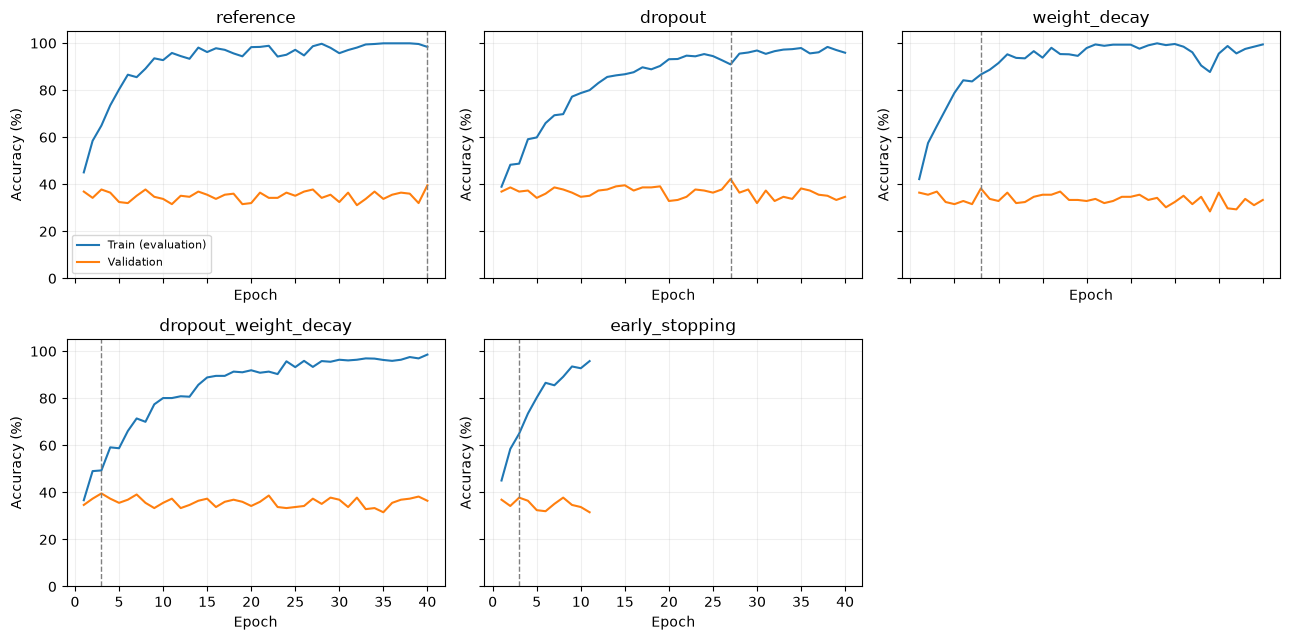

MLP selected on validation: dropout


In [28]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, (name, result) in zip(axes.flat, mlp_results.items()):
    run_history = pd.read_csv(REGULARIZATION_DIR / name / "training_history.csv")
    ax.plot(run_history["epoch"], 100 * run_history["train_accuracy"], label="Train (evaluation)")
    ax.plot(run_history["epoch"], 100 * run_history["validation_accuracy"], label="Validation")
    ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Epoch", ylabel="Accuracy (%)", ylim=(0, 105))
    ax.grid(alpha=0.2)
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

best_mlp_name = max(mlp_results, key=lambda name: (
    mlp_results[name]["best_validation_accuracy"], -mlp_results[name]["best_validation_loss"]
))
print("MLP selected on validation:", best_mlp_name)


### What these experiments change

The best MLP in this comparison uses **dropout: 42.2% validation accuracy at epoch 27**,
versus 39.6% for the rerun baseline. That is six more correctly classified images out of 225.
Its training score, measured in evaluation mode at that epoch, is still 91.0%:
the gap remains **48.7 percentage points**, versus 58.8 for the baseline. Overfitting remains substantial.

Weight decay alone gives 38.2%. Dropout plus weight decay reaches 39.6% at epoch 3,
with only 49.3% training accuracy at that epoch. Its small gap does not make it a better model:
both scores are low. Early stopping ends at epoch 11 and selects epoch 3, at 37.8%.
With a patience of eight epochs, it misses later improvements seen in the baseline.

We keep dropout as the **MLP candidate for subsequent comparisons**, using the predetermined validation criterion.
Several settings were tried on the same small validation set with one seed: the 2.7-point gain alone
does not establish reproducible superiority. No test score has been calculated at this stage.


### Which styles remain difficult for the MLP?

This is the selected MLP's validation confusion matrix. Rows show true styles.
Cubism remains particularly difficult: three of 45 images are correctly recognized,
with frequent predictions of Baroque (14) and Ukiyo-e (13).


In [29]:
mlp_confusion = pd.read_csv(
    REGULARIZATION_DIR / best_mlp_name / "validation_confusion.csv", index_col=0
)
display(mlp_confusion)
mlp_recall = 100 * pd.Series(
    mlp_confusion.values.diagonal() / mlp_confusion.sum(axis=1).values,
    index=mlp_confusion.index, name="Validation accuracy (%)",
)
mlp_recall.round(1).to_frame()


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
true_style,,,,,
Baroque,32,2,5,2,4
Cubism,14,3,8,7,13
Impressionism,17,2,14,4,8
Pop_Art,9,4,5,17,10
Ukiyo_e,4,1,7,4,29


,Validation accuracy (%)
true_style,
Baroque,71.1
Cubism,6.7
Impressionism,31.1
Pop_Art,37.8
Ukiyo_e,64.4


## 7. Step 6 — reuse a pretrained ResNet

The MLP starts from pixels and learns all its weights from only 1,050 images.
We now try **ResNet-18 with ImageNet weights**, replacing its last layer with five outputs.
All other layers are frozen and remain in evaluation mode: BatchNorm statistics must not change while training the head.

The [torchvision weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
have their own preprocessing: resize to 256, crop to 224 and ImageNet normalization.
Our files are already 128 × 128, so enlarging them adds no detail. Differences from the MLP therefore
combine pretraining, architecture and image preprocessing.

Because the backbone does not change and there is no random augmentation, its features are computed once
for training and validation. The small final layer is then trained on these 512-value vectors.
This follows PyTorch's [feature extraction approach](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial).


In [30]:
from torch.utils.data import TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

RESNET_DIR = ROOT / "outputs/resnet18_head"
RESNET_CONFIG = {
    "name": "resnet18_head", "weights": "ResNet18_Weights.IMAGENET1K_V1",
    "seed": SEED, "epochs": 60, "learning_rate": 1e-3, "weight_decay": 1e-4,
    "batch_size": 64, "extraction_batch_size": 32, "patience": 10,
    "trainable_layers": ["fc"], "feature_size": 512,
    "checkpoint_selection": "validation accuracy, then validation loss",
}
RESNET_CONFIG


{'name': 'resnet18_head',
 'weights': 'ResNet18_Weights.IMAGENET1K_V1',
 'seed': 42,
 'epochs': 60,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'batch_size': 64,
 'extraction_batch_size': 32,
 'patience': 10,
 'trainable_layers': ['fc'],
 'feature_size': 512,
 'checkpoint_selection': 'validation accuracy, then validation loss'}

### Freeze the network and prepare features

We use exactly the same paths and labels as for the MLP. Test images are not loaded.
We check the number of trainable parameters and the backbone's hash before and after the experiment
to ensure that only the final layer's values have changed.


In [31]:
def backbone_digest(model):
    digest = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        if not name.startswith("fc."):
            digest.update(name.encode())
            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


@torch.no_grad()
def extract_features(extractor, dataset, batch_size, extraction_device):
    extractor.eval()
    features, targets = [], []
    for images, labels in DataLoader(dataset, batch_size=batch_size, shuffle=False):
        features.append(extractor(images.to(extraction_device)).cpu())
        targets.append(labels)
    return TensorDataset(torch.cat(features), torch.cat(targets))


def run_resnet_head():
    set_seed(SEED)
    experiment_device = choose_device(MLP_CONFIG.device)
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)
    model.requires_grad_(False)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model = model.to(experiment_device)
    model.eval()
    before_digest = backbone_digest(model)
    assert all(not p.requires_grad for name, p in model.named_parameters() if not name.startswith("fc."))
    assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 2565

    # Reuse the selected rows without constructing a test set.
    image_datasets = {
        split: ManifestImageDataset(DATA_DIR, loaders[split].dataset.records, weights.transforms())
        for split in ("train", "validation")
    }
    extractor = nn.Sequential(*list(model.children())[:-1], nn.Flatten()).to(experiment_device)
    extraction_start = time.perf_counter()
    feature_datasets = {}
    for split, dataset in image_datasets.items():
        print("Extraction :", split, len(dataset), "images", flush=True)
        feature_datasets[split] = extract_features(
            extractor, dataset, RESNET_CONFIG["extraction_batch_size"], experiment_device
        )
    extraction_seconds = time.perf_counter() - extraction_start
    assert not any(module.training for module in extractor.modules())
    generator = torch.Generator().manual_seed(SEED)
    feature_loaders = {
        split: DataLoader(dataset, batch_size=RESNET_CONFIG["batch_size"],
                          shuffle=(split == "train"), generator=generator if split == "train" else None)
        for split, dataset in feature_datasets.items()
    }
    print("Trainable parameters :", sum(p.numel() for p in model.parameters() if p.requires_grad), flush=True)
    records, result = fit_experiment(
        model.fc, feature_loaders, epochs=RESNET_CONFIG["epochs"],
        learning_rate=RESNET_CONFIG["learning_rate"], weight_decay=RESNET_CONFIG["weight_decay"],
        patience=RESNET_CONFIG["patience"], seed=SEED, experiment_device=experiment_device,
    )
    after_digest = backbone_digest(model)
    assert before_digest == after_digest, "The frozen backbone parameters or statistics changed."
    matrix = validation_confusion(model.fc, feature_loaders["validation"], len(class_names), experiment_device)
    preprocessing = weights.transforms()
    result.update({
        "model": "ResNet-18 frozen backbone + linear head", "device": str(experiment_device),
        "parameter_count": sum(p.numel() for p in model.parameters()),
        "trainable_parameter_count": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "feature_extraction_seconds": extraction_seconds,
        "backbone_sha256_before": before_digest, "backbone_sha256_after": after_digest,
        "backbone_unchanged": before_digest == after_digest,
        "split_counts": {split: len(dataset) for split, dataset in image_datasets.items()},
        "feature_shapes": {split: list(dataset.tensors[0].shape) for split, dataset in feature_datasets.items()},
        "preprocessing": {"resize": preprocessing.resize_size, "crop": preprocessing.crop_size,
                          "mean": preprocessing.mean, "std": preprocessing.std},
    })
    save_experiment(model, records, result, RESNET_DIR, RESNET_CONFIG, class_names, matrix,
                    extra_checkpoint={"preprocessing": result["preprocessing"]})
    print(f"Best validation: {result['best_validation_accuracy']:.1%} at epoch {result['best_epoch']}", flush=True)

if RUN_RESNET_HEAD:
    run_resnet_head()


In [32]:
resnet_summary_path = RESNET_DIR / "validation_summary.json"
if not resnet_summary_path.is_file():
    raise FileNotFoundError("ResNet results missing: set RUN_RESNET_HEAD = True.")
resnet_result = json.loads(resnet_summary_path.read_text(encoding="utf-8"))
resnet_history = pd.read_csv(RESNET_DIR / "training_history.csv")
print("Trainable parameters :", resnet_result["trainable_parameter_count"])
print("Backbone unchanged:", resnet_result["backbone_unchanged"])
print(f"Feature extraction: {resnet_result['feature_extraction_seconds']:.1f} s")
print(f"Head training: {resnet_result['training_seconds']:.1f} s")
print("Best epoch:", resnet_result["best_epoch"])
print(f"Training accuracy: {resnet_result['train_accuracy_at_best_epoch']:.1%}")
print(f"Validation accuracy: {resnet_result['best_validation_accuracy']:.1%}")
print("Test evaluated:", resnet_result["test_evaluated"])


Trainable parameters : 2565
Backbone unchanged: True
Feature extraction: 5.2 s
Head training: 1.3 s
Best epoch: 16
Training accuracy: 87.9%
Validation accuracy: 75.6%
Test evaluated: False


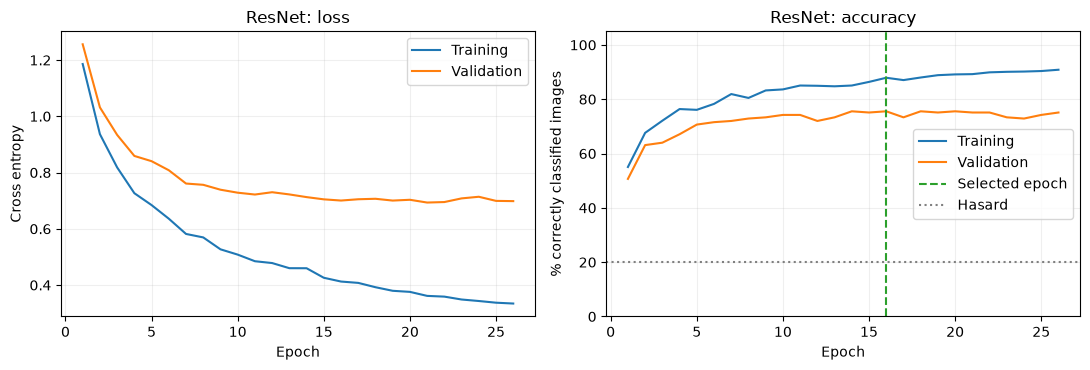

In [33]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
for split, label in (("train", "Training"), ("validation", "Validation")):
    ax_loss.plot(resnet_history["epoch"], resnet_history[f"{split}_loss"], label=label)
    ax_acc.plot(resnet_history["epoch"], 100 * resnet_history[f"{split}_accuracy"], label=label)
ax_loss.set(title="ResNet: loss", xlabel="Epoch", ylabel="Cross entropy")
ax_acc.set(title="ResNet: accuracy", xlabel="Epoch", ylabel="% correctly classified images", ylim=(0, 105))
ax_acc.axvline(resnet_result["best_epoch"], color="tab:green", linestyle="--", label="Selected epoch")
ax_acc.axhline(20, color="gray", linestyle=":", label="Hasard")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


### Which styles are confused?

Rows show true styles and columns show predictions; the diagonal contains correct predictions.
These results cover the 225 validation images.


In [34]:
resnet_confusion = pd.read_csv(RESNET_DIR / "validation_confusion.csv", index_col=0)
display(resnet_confusion)
per_style = 100 * pd.Series(
    resnet_confusion.values.diagonal() / resnet_confusion.sum(axis=1).values,
    index=resnet_confusion.index, name="Validation accuracy (%)",
)
display(per_style.round(1).to_frame())

pd.DataFrame({
    "Model": [f"MLP ({best_mlp_name})", "ResNet-18, head only"],
    "Validation (%)": [100 * mlp_results[best_mlp_name]["best_validation_accuracy"],
                        100 * resnet_result["best_validation_accuracy"]],
    "Trainable parameters": [mlp_results[best_mlp_name]["parameter_count"],
                                resnet_result["trainable_parameter_count"]],
}).set_index("Model").round(2)


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
true_style,,,,,
Baroque,35,2,5,1,2
Cubism,1,33,1,8,2
Impressionism,6,1,36,2,0
Pop_Art,2,8,5,26,4
Ukiyo_e,0,2,3,0,40


,Validation accuracy (%)
true_style,
Baroque,77.8
Cubism,73.3
Impressionism,80.0
Pop_Art,57.8
Ukiyo_e,88.9


,Validation (%),Trainable parameters
Model,,
MLP (dropout),42.22,3179525
"ResNet-18, head only",75.56,2565


### Observations with ImageNet features

The ResNet head reaches **75.6% validation accuracy** (170 of 225 images) at epoch 16.
Training accuracy is 87.9% at that epoch, a gap of **12.3 percentage points**.
Early stopping ends the run at epoch 26. Only **2,565 parameters** are trained;
the backbone hash is unchanged before and after the experiment, including BatchNorm statistics.

The score exceeds the dropout MLP by 33.3 points on this split. Pretrained features are a promising starting point.
This experiment cannot isolate the effect of pretraining, since architecture and image preprocessing also change.

Not all styles are recognized equally well: **Ukiyo-e reaches 88.9%**, versus **57.8% for Pop Art**.
Pop Art and Cubism are confused eight times in each direction. The matrix shows where to look,
but does not identify which visual details cause the errors.

This does not yet determine the kiosk model. ResNet retains more than eleven million total parameters,
even though only its head was trained. We still need CPU latency measurements and a classical-model comparison.
The test remains reserved for the final comparison in step 8, after selection.


## 8. Step 7 — adapt the last ResNet block

The head-only model uses ImageNet features. Starting from its best weights, we now allow **`layer4`
and the final layer** to adapt to paintings, with a learning rate of 0.0001 instead of 0.001.
The rest of the network is frozen.

[BatchNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html) statistics stay fixed,
including in `layer4`, while its affine parameters remain trainable. The prefix through `layer3` is computed
once for training and validation. There is still no random augmentation.

We use at most 20 epochs with a patience of five. The initial checkpoint is also a candidate:
if fine-tuning does not improve validation, it is retained. Epoch 0 in the plots is this starting point.


In [35]:
FINETUNE_DIR = ROOT / "outputs/resnet18_finetuned"
FINETUNE_CONFIG = {
    "name": "resnet18_layer4", "seed": SEED, "epochs": 20,
    "learning_rate": 1e-4, "weight_decay": 1e-4, "patience": 5,
    "batch_size": 32, "extraction_batch_size": 32,
    "trainable_layers": ["layer4", "fc"], "batchnorm_running_statistics": "frozen",
    "initial_checkpoint_is_candidate": True,
    "checkpoint_selection": "validation accuracy, then validation loss",
}

class ResNetTail(nn.Module):
    def __init__(self, resnet):
        super().__init__()
        self.layer4, self.avgpool, self.fc = resnet.layer4, resnet.avgpool, resnet.fc

    def train(self, mode=True):
        super().train(mode)
        # The layer4 affine parameters are trained; BatchNorm statistics remain fixed.
        for module in self.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
        return self

    def forward(self, features):
        return self.fc(torch.flatten(self.avgpool(self.layer4(features)), 1))

FINETUNE_CONFIG


{'name': 'resnet18_layer4',
 'seed': 42,
 'epochs': 20,
 'learning_rate': 0.0001,
 'weight_decay': 0.0001,
 'patience': 5,
 'batch_size': 32,
 'extraction_batch_size': 32,
 'trainable_layers': ['layer4', 'fc'],
 'batchnorm_running_statistics': 'frozen',
 'initial_checkpoint_is_candidate': True,
 'checkpoint_selection': 'validation accuracy, then validation loss'}

In [36]:
def state_digest(model, include):
    digest = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        if include(name):
            digest.update(name.encode())
            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def run_layer4_finetuning():
    set_seed(SEED)
    experiment_device = choose_device(MLP_CONFIG.device)
    checkpoint_path = ROOT / resnet_result["checkpoint"]
    if not checkpoint_path.is_file():
        raise FileNotFoundError("Head checkpoint missing: rerun step 6 with RUN_RESNET_HEAD = True.")
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert checkpoint["class_names"] == class_names
    assert resnet_result["manifest_sha256"] == hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model.load_state_dict(checkpoint["model_state_dict"])
    model.requires_grad_(False)
    model.layer4.requires_grad_(True)
    model.fc.requires_grad_(True)
    model.to(experiment_device).eval()
    frozen = lambda name: not name.startswith(("layer4.", "fc."))
    bn_buffer = lambda name: name.endswith(("running_mean", "running_var", "num_batches_tracked"))
    frozen_before = state_digest(model, frozen)
    bn_before = state_digest(model, bn_buffer)
    trainable_before = state_digest(model, lambda name: name.startswith(("layer4.", "fc.")))
    trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
    assert all(name.startswith(("layer4.", "fc.")) for name in trainable_names)

    # The frozen prefix is deterministic: compute it once, without random augmentation.
    prefix = nn.Sequential(model.conv1, model.bn1, model.relu, model.maxpool,
                           model.layer1, model.layer2, model.layer3).eval()
    transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
    feature_datasets = {}
    extraction_started = time.perf_counter()
    for split in ("train", "validation"):
        dataset = ManifestImageDataset(DATA_DIR, loaders[split].dataset.records, transform)
        print("Prefix extraction:", split, len(dataset), "images", flush=True)
        feature_datasets[split] = extract_features(
            prefix, dataset, FINETUNE_CONFIG["extraction_batch_size"], experiment_device
        )
    extraction_seconds = time.perf_counter() - extraction_started
    generator = torch.Generator().manual_seed(SEED)
    feature_loaders = {
        split: DataLoader(dataset, batch_size=FINETUNE_CONFIG["batch_size"], shuffle=(split == "train"),
                          generator=generator if split == "train" else None)
        for split, dataset in feature_datasets.items()
    }
    tail = ResNetTail(model).to(experiment_device).eval()
    initial_state = {key: value.detach().cpu().clone() for key, value in tail.state_dict().items()}
    loss_function = nn.CrossEntropyLoss()
    initial_train = validate_epoch(tail, feature_loaders["train"], loss_function, experiment_device)
    initial_val = validate_epoch(tail, feature_loaders["validation"], loss_function, experiment_device)
    print(f"Before fine-tuning: validation {initial_val[1]:.1%}", flush=True)
    print("Trainable parameters :", sum(p.numel() for p in model.parameters() if p.requires_grad), flush=True)
    records, result = fit_experiment(
        tail, feature_loaders, epochs=FINETUNE_CONFIG["epochs"],
        learning_rate=FINETUNE_CONFIG["learning_rate"], weight_decay=FINETUNE_CONFIG["weight_decay"],
        patience=FINETUNE_CONFIG["patience"], seed=SEED, experiment_device=experiment_device,
    )
    if not checkpoint_improves(result["best_validation_accuracy"], result["best_validation_loss"],
                               initial_val[1], initial_val[0]):
        tail.load_state_dict(initial_state)
        result.update(best_epoch=0, best_validation_accuracy=initial_val[1], best_validation_loss=initial_val[0],
                      train_accuracy_at_best_epoch=initial_train[1],
                      train_validation_accuracy_gap=initial_train[1] - initial_val[1])
    records.insert(0, {
        "epoch": 0, "train_loss": initial_train[0], "train_accuracy": initial_train[1],
        "validation_loss": initial_val[0], "validation_accuracy": initial_val[1],
        "online_train_loss": None, "online_train_accuracy": None,
        "learning_rate": FINETUNE_CONFIG["learning_rate"],
    })
    frozen_after = state_digest(model, frozen)
    bn_after = state_digest(model, bn_buffer)
    assert frozen_before == frozen_after, "The frozen prefix changed."
    assert bn_before == bn_after, "BatchNorm statistics changed."
    matrix = validation_confusion(tail, feature_loaders["validation"], len(class_names), experiment_device)
    result.update({
        "model": "ResNet-18 layer4 + fc fine-tuning", "device": str(experiment_device),
        "parameter_count": sum(p.numel() for p in model.parameters()),
        "trainable_parameter_count": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "feature_extraction_seconds": extraction_seconds,
        "frozen_prefix_sha256_before": frozen_before, "frozen_prefix_sha256_after": frozen_after,
        "frozen_prefix_unchanged": frozen_before == frozen_after,
        "batchnorm_buffers_sha256_before": bn_before, "batchnorm_buffers_sha256_after": bn_after,
        "batchnorm_buffers_unchanged": bn_before == bn_after,
        "trainable_layers_changed": trainable_before != state_digest(model, lambda name: name.startswith(("layer4.", "fc."))),
        "source_checkpoint": checkpoint_path.relative_to(ROOT).as_posix(),
        "source_checkpoint_sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
        "initial_validation_accuracy": initial_val[1],
        "feature_shapes": {split: list(dataset.tensors[0].shape) for split, dataset in feature_datasets.items()},
        "preprocessing": resnet_result["preprocessing"],
    })
    save_experiment(model, records, result, FINETUNE_DIR, FINETUNE_CONFIG, class_names, matrix,
                    extra_checkpoint={"preprocessing": result["preprocessing"]})
    print(f"Selected checkpoint: epoch {result['best_epoch']}, validation {result['best_validation_accuracy']:.1%}", flush=True)

if RUN_FINETUNING:
    run_layer4_finetuning()


In [37]:
finetune_summary_path = FINETUNE_DIR / "validation_summary.json"
if not finetune_summary_path.is_file():
    raise FileNotFoundError("Fine-tuning results missing: set RUN_FINETUNING = True.")
finetune_result = json.loads(finetune_summary_path.read_text(encoding="utf-8"))
finetune_history = pd.read_csv(FINETUNE_DIR / "training_history.csv")
print("Trainable parameters :", finetune_result["trainable_parameter_count"])
print("Frozen prefix unchanged:", finetune_result["frozen_prefix_unchanged"])
print("BatchNorm statistics unchanged:", finetune_result["batchnorm_buffers_unchanged"])
print("Trainable layer weights changed:", finetune_result["trainable_layers_changed"])
print(f"Validation before fine-tuning: {finetune_result['initial_validation_accuracy']:.1%}")
print(f"Selected validation: {finetune_result['best_validation_accuracy']:.1%}, epoch {finetune_result['best_epoch']}")
print("Epochs trained:", finetune_result["epochs_run"])


Trainable parameters : 8396293
Frozen prefix unchanged: True
BatchNorm statistics unchanged: True
Trainable layer weights changed: True
Validation before fine-tuning: 75.6%
Selected validation: 79.6%, epoch 8
Epochs trained: 13


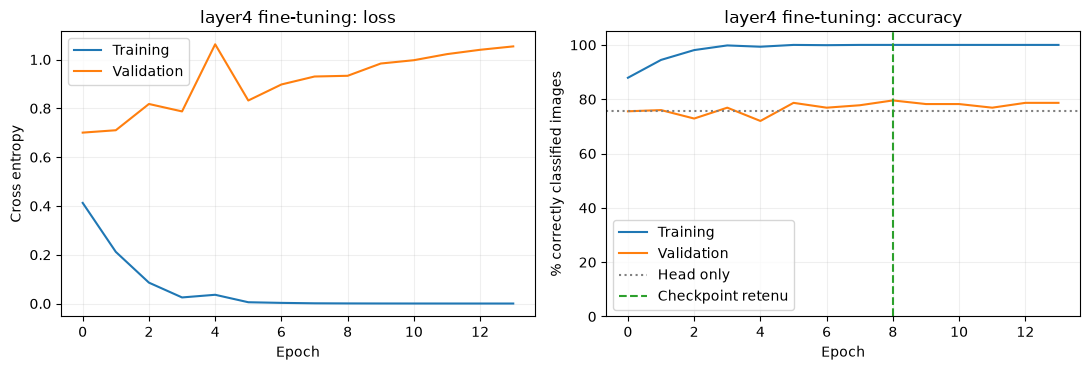

In [38]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
for split, label in (("train", "Training"), ("validation", "Validation")):
    ax_loss.plot(finetune_history["epoch"], finetune_history[f"{split}_loss"], label=label)
    ax_acc.plot(finetune_history["epoch"], 100 * finetune_history[f"{split}_accuracy"], label=label)
ax_loss.set(title="layer4 fine-tuning: loss", xlabel="Epoch", ylabel="Cross entropy")
ax_acc.set(title="layer4 fine-tuning: accuracy", xlabel="Epoch", ylabel="% correctly classified images", ylim=(0, 105))
ax_acc.axhline(100 * finetune_result["initial_validation_accuracy"], color="gray", linestyle=":", label="Head only")
ax_acc.axvline(finetune_result["best_epoch"], color="tab:green", linestyle="--", label="Checkpoint retenu")
for ax in (ax_loss, ax_acc):
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### What fine-tuning adds

The best checkpoint is at **epoch 8: 79.6% validation accuracy**, nine more correctly classified paintings
than the head alone (75.6%). The run stops at epoch 13. The prefix through `layer3` and BatchNorm statistics
are unchanged; the `layer4` and head weights have changed.

The selected checkpoint nevertheless reaches 100% on training, a gap of 20.4 points.
Its validation loss is also higher than the head-only model's (0.933 versus 0.701).
It recognizes more images, but some errors are more confident: the accuracy gain does not solve everything.

We select this fine-tuned model within the ResNet family using the accuracy criterion set before the experiments.
This remains a comparison on one seed and a small validation set.


## 9. Step 8 — compare with a classical model

We train **multinomial logistic regression** on the same normalized 64 × 64 RGB pixels as the MLP.
It receives 12,288 values, with no hidden layer or ImageNet features, providing a simple baseline for the dense network.

The first sweep, from 0.001 to 10, selected the strongest regularization. We therefore add 0.00001 and 0.0001
before looking at the test, to check that boundary of the grid. Seven `C` values are compared.
In [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
a small `C` strengthens L2 regularization. We select by validation accuracy, breaking ties by loss.
Parameters are fitted on training only; we do not retrain on training plus validation.
We also check solver convergence before comparing scores.


In [39]:
import joblib
import numpy as np
import sklearn
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from threadpoolctl import threadpool_limits

LOGISTIC_DIR = ROOT / "outputs/logistic_regression"
LOGISTIC_CONFIG = {
    "C_values": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0], "solver": "lbfgs", "tol": 1e-4,
    "max_iter": 1000, "seed": SEED, "input_size": 64,
    "normalization_mean": list(NORMALIZE_MEAN), "normalization_std": list(NORMALIZE_STD),
    "features": "flattened RGB pixels", "fit_threads": 1,
    "selection": "validation accuracy, then validation log loss",
}


def dataset_as_numpy(dataset):
    values, targets = [], []
    for images, labels in DataLoader(dataset, batch_size=64, shuffle=False):
        values.append(images.flatten(1).numpy())
        targets.append(labels.numpy())
    return np.ascontiguousarray(np.concatenate(values), dtype=np.float64), np.concatenate(targets)


def run_logistic_regression():
    x_train, y_train = dataset_as_numpy(loaders["train"].dataset)
    x_val, y_val = dataset_as_numpy(loaders["validation"].dataset)
    LOGISTIC_DIR.mkdir(parents=True, exist_ok=True)
    records, best_model, best_key = [], None, (-1.0, -float("inf"))
    started = time.perf_counter()
    with threadpool_limits(limits=1):
        for c_value in LOGISTIC_CONFIG["C_values"]:
            fit_started = time.perf_counter()
            # Do not select an unconverged solver: allow more iterations if needed.
            for maximum in (LOGISTIC_CONFIG["max_iter"], 5000):
                classifier = LogisticRegression(C=c_value, solver=LOGISTIC_CONFIG["solver"],
                    max_iter=maximum, tol=LOGISTIC_CONFIG["tol"], random_state=SEED)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    classifier.fit(x_train, y_train)
                converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
                if converged:
                    break
            if not converged:
                raise RuntimeError(f"Logistic regression did not converge for C={c_value}.")
            train_probabilities, val_probabilities = classifier.predict_proba(x_train), classifier.predict_proba(x_val)
            train_accuracy = accuracy_score(y_train, classifier.classes_[train_probabilities.argmax(axis=1)])
            val_accuracy = accuracy_score(y_val, classifier.classes_[val_probabilities.argmax(axis=1)])
            val_loss = log_loss(y_val, val_probabilities, labels=np.arange(len(class_names)))
            record = {"C": c_value, "train_accuracy": train_accuracy, "validation_accuracy": val_accuracy,
                      "validation_loss": val_loss, "iterations": int(classifier.n_iter_.max()),
                      "max_iter": maximum, "converged": converged, "fit_seconds": time.perf_counter() - fit_started}
            records.append(record)
            print(f"C={c_value:g} : train {train_accuracy:.1%}, validation {val_accuracy:.1%}, {record['iterations']} iterations", flush=True)
            if (val_accuracy, -val_loss) > best_key:
                best_key, best_model, best_record = (val_accuracy, -val_loss), classifier, record.copy()

    folder = LOGISTIC_DIR / "checkpoints"
    folder.mkdir(exist_ok=True)
    checkpoint = folder / "best.joblib"
    joblib.dump(best_model, checkpoint, compress=0)
    matrix = confusion_matrix(y_val, best_model.predict(x_val), labels=np.arange(len(class_names)))
    pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis("true_style").to_csv(
        LOGISTIC_DIR / "validation_confusion.csv"
    )
    pd.DataFrame(records).to_csv(LOGISTIC_DIR / "validation_search.csv", index=False)
    result = {
        "model": "Multinomial logistic regression on RGB pixels", "config": LOGISTIC_CONFIG,
        "best_C": best_record["C"], "best_validation_accuracy": best_record["validation_accuracy"],
        "best_validation_loss": best_record["validation_loss"],
        "train_accuracy_at_best_epoch": best_record["train_accuracy"],
        "parameter_count": int(best_model.coef_.size + best_model.intercept_.size),
        "iterations": best_record["iterations"], "converged": True,
        "training_seconds": time.perf_counter() - started, "test_evaluated": False,
        "checkpoint": checkpoint.relative_to(ROOT).as_posix(), "class_names": class_names,
        "manifest": MANIFEST_PATH.relative_to(ROOT).as_posix(),
        "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
        "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__, "python": sys.version.split()[0]},
    }
    (LOGISTIC_DIR / "validation_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print(f"Selected C: {best_record['C']:g}, validation {best_record['validation_accuracy']:.1%}", flush=True)

if RUN_LOGISTIC_REGRESSION:
    run_logistic_regression()


In [40]:
logistic_summary_path = LOGISTIC_DIR / "validation_summary.json"
if not logistic_summary_path.is_file():
    raise FileNotFoundError("Classical model results missing: set RUN_LOGISTIC_REGRESSION = True.")
logistic_result = json.loads(logistic_summary_path.read_text(encoding="utf-8"))
logistic_search = pd.read_csv(LOGISTIC_DIR / "validation_search.csv")
search_table = logistic_search[["C", "train_accuracy", "validation_accuracy", "validation_loss", "iterations", "converged"]].copy()
search_table["C"] = search_table["C"].map(lambda value: f"{value:g}")
display(search_table.round(4))
print("Selected C:", logistic_result["best_C"])
print(f"Validation : {logistic_result['best_validation_accuracy']:.1%}")
print("Parameters :", logistic_result["parameter_count"])


,C,train_accuracy,validation_accuracy,validation_loss,iterations,converged
0,1e-05,0.3905,0.3289,1.5394,28,True
1,0.0001,0.4990,0.3778,1.5006,90,True
2,0.001,0.7000,0.3822,1.5270,167,True
3,0.01,0.9590,0.3378,1.8209,284,True
4,0.1,0.9981,0.3067,2.6462,318,True
5,1,1.0000,0.2933,3.8381,272,True
6,10,1.0000,0.2756,7.1033,130,True


Selected C: 0.001
Validation : 38.2%
Parameters : 61445


### Linear model results

The grid selects **C = 0.001**, with **38.2% validation accuracy** and 70.0% training accuracy.
All seven fits converged. As regularization decreases, the model eventually reaches 100% on training,
but validation drops to 27.6% for C = 10.

The dropout MLP performs better on validation (42.2%), but the difference is nine images out of 225.
Logistic regression uses only 61,445 coefficients and biases, compared with over three million MLP parameters.
CPU measurements and file sizes will show the cost of this small gain.


### Select before looking at the test

We select one model per family: the best MLP from step 5, the better ResNet and logistic regression
with the selected `C`. Selection maximizes validation accuracy, breaking ties by lowest loss.
No weights or hyperparameters are subsequently adjusted.

The selection and each checkpoint's hash are written to `outputs/final_comparison/selection.json`
before test images are opened. One pass over the 225 images is allowed for each of the three models.
A reservation of the results file prevents recalculating this score by rerunning the cell.
By default, the notebook reloads existing results.


In [41]:
resnet_candidates = {"head": resnet_result, "layer4": finetune_result}
chosen_resnet = max(resnet_candidates, key=lambda name: (
    resnet_candidates[name]["best_validation_accuracy"], -resnet_candidates[name]["best_validation_loss"]
))
pd.DataFrame([
    {"Family": "MLP", "Choice": best_mlp_name, "Validation (%)": 100 * mlp_results[best_mlp_name]["best_validation_accuracy"]},
    {"Family": "ResNet-18", "Choice": chosen_resnet, "Validation (%)": 100 * resnet_candidates[chosen_resnet]["best_validation_accuracy"]},
    {"Family": "Logistic regression", "Choice": f"C={logistic_result['best_C']:g}", "Validation (%)": 100 * logistic_result["best_validation_accuracy"]},
]).set_index("Family").round(2)


,Choice,Validation (%)
Family,,
MLP,dropout,42.22
ResNet-18,layer4,79.56
Logistic regression,C=0.001,38.22


### CPU response time and model size

We measure prediction one image at a time with **one CPU thread**, ten warm-up passes and 100 measurements.
We use ten validation images already loaded in RGB. We report the median and 95th percentile for the model
alone and with resizing and normalization. File reading and JPEG decoding are excluded, so this is not
the full time for a camera request.

The entire ResNet is measured without a feature cache. Size is the uncompressed checkpoint with weights and metadata.
This protocol compares the three models on this machine; it does not replace a test on the actual kiosk CPU.


In [42]:
import platform

FINAL_DIR = ROOT / "outputs/final_comparison"
BENCHMARK_CONFIG = {"threads": 1, "batch_size": 1, "warmup": 10, "repeats": 100,
                    "validation_images": 10, "includes_disk_io": False, "includes_image_decoding": False}


def selection_payload():
    resnet_candidates = {"head": resnet_result, "layer4": finetune_result}
    resnet_choice = max(resnet_candidates, key=lambda name: (
        resnet_candidates[name]["best_validation_accuracy"], -resnet_candidates[name]["best_validation_loss"]
    ))
    choices = {"mlp": (best_mlp_name, mlp_results[best_mlp_name]),
               "resnet": (resnet_choice, resnet_candidates[resnet_choice]),
               "logistic": (f"C={logistic_result['best_C']:g}", logistic_result)}
    manifest_hash = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
    models = {}
    for family, (variant, result) in choices.items():
        assert result["manifest_sha256"] == manifest_hash
        assert result["class_names"] == class_names
        checkpoint = ROOT / result["checkpoint"]
        if not checkpoint.is_file():
            raise FileNotFoundError(f"Checkpoint missing: {checkpoint}. Rerun the corresponding step.")
        models[family] = {
            "variant": variant, "checkpoint": result["checkpoint"],
            "checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
            "validation_accuracy": result["best_validation_accuracy"],
            "validation_loss": result["best_validation_loss"],
            "parameter_count": result["parameter_count"], "config": result["config"],
        }
    return {"models": models, "class_names": class_names, "seed": SEED,
            "manifest": MANIFEST_PATH.relative_to(ROOT).as_posix(), "manifest_sha256": manifest_hash,
            "selection_rule": "best validation accuracy within each family, then lowest validation loss",
            "refit_on_train_and_validation": False}


def freeze_final_selection():
    if (FINAL_DIR / "test_evaluation.json").exists():
        raise FileExistsError("The test has already been reserved or evaluated. Read the results; do not rerun it.")
    selection = selection_payload()
    FINAL_DIR.mkdir(parents=True, exist_ok=True)
    path = FINAL_DIR / "selection.json"
    if path.exists():
        if json.loads(path.read_text(encoding="utf-8")) != selection:
            raise RuntimeError("The saved selection differs from the current models. Do not change choices after the test.")
    else:
        with path.open("x", encoding="utf-8") as stream:
            json.dump(selection, stream, indent=2, ensure_ascii=False)
            stream.write("\n")
    return selection


def load_final_models(selection):
    models = {}
    for family, selected in selection["models"].items():
        path = ROOT / selected["checkpoint"]
        if hashlib.sha256(path.read_bytes()).hexdigest() != selected["checkpoint_sha256"]:
            raise RuntimeError(f"Le checkpoint {family} has changed since selection.")
        if family == "logistic":
            models[family] = joblib.load(path)
            assert np.array_equal(models[family].classes_, np.arange(len(class_names)))
        else:
            checkpoint = torch.load(path, map_location="cpu", weights_only=True)
            if family == "mlp":
                model = RegularizedMLP(len(class_names), selected["config"]["dropout"])
            else:
                model = resnet18(weights=None)
                model.fc = nn.Linear(model.fc.in_features, len(class_names))
            model.load_state_dict(checkpoint["model_state_dict"])
            models[family] = model.cpu().eval().requires_grad_(False)
    return models


def final_preprocessors():
    return {
        "pixels": transforms.Compose([transforms.Resize((64, 64)), transforms.ToTensor(),
                                      transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD)]),
        "resnet": ResNet18_Weights.IMAGENET1K_V1.transforms(),
    }


def benchmark_cpu(models, selection):
    preprocess = final_preprocessors()
    sample = random.Random(SEED).sample(loaders["validation"].dataset.records, BENCHMARK_CONFIG["validation_images"])
    images = []
    for record in sample:
        with Image.open(DATA_DIR / record["relative_path"]) as image:
            images.append(image.convert("RGB"))
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(BENCHMARK_CONFIG["threads"])
    records = []
    try:
        with threadpool_limits(limits=BENCHMARK_CONFIG["threads"]), torch.inference_mode():
            for family, model in models.items():
                def prepare(image):
                    tensor = preprocess["resnet" if family == "resnet" else "pixels"](image).unsqueeze(0)
                    return np.ascontiguousarray(tensor.flatten(1).numpy(), dtype=np.float64) if family == "logistic" else tensor

                def predict(value):
                    return model.predict(value) if family == "logistic" else model(value).argmax(dim=1)

                prepared = [prepare(image) for image in images]
                for i in range(BENCHMARK_CONFIG["warmup"]):
                    predict(prepared[i % len(prepared)])
                timings = {}
                for mode in ("model_only", "with_preprocessing"):
                    elapsed = []
                    for i in range(BENCHMARK_CONFIG["repeats"]):
                        index = i % len(images)
                        started = time.perf_counter_ns()
                        value = prepared[index] if mode == "model_only" else prepare(images[index])
                        predict(value)
                        elapsed.append((time.perf_counter_ns() - started) / 1e6)
                    timings[f"{mode}_median_ms"] = float(np.median(elapsed))
                    timings[f"{mode}_p95_ms"] = float(np.percentile(elapsed, 95))
                selected = selection["models"][family]
                records.append({"family": family, "variant": selected["variant"], **timings,
                                "parameter_count": selected["parameter_count"],
                                "checkpoint_bytes": (ROOT / selected["checkpoint"]).stat().st_size})
    finally:
        torch.set_num_threads(previous_threads)
    pd.DataFrame(records).to_csv(FINAL_DIR / "cpu_benchmark.csv", index=False)
    metadata = {**BENCHMARK_CONFIG, "machine": platform.machine(), "processor": platform.processor(),
                "logical_cpus": os.cpu_count(), "python": sys.version.split()[0], "torch": torch.__version__,
                "numpy": np.__version__, "sklearn": sklearn.__version__,
                "measurement": "median and p95 of single-image prediction, loaded RGB image, no disk I/O or decoding",
                "checkpoint_format": "uncompressed torch checkpoint or uncompressed joblib classifier"}
    (FINAL_DIR / "cpu_benchmark_protocol.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
    return records


def predict_image_records(records, models, inference_device, batch_size=32):
    preprocess = final_preprocessors()
    probabilities = {family: [] for family in models}
    targets, prediction_rows = [], []
    for family in ("mlp", "resnet"):
        models[family].to(inference_device).eval()
    with torch.inference_mode(), threadpool_limits(limits=1):
        for start in range(0, len(records), batch_size):
            batch = records[start:start + batch_size]
            pixels, resnet_inputs, labels = [], [], []
            for record in batch:
                path = (DATA_DIR / record["relative_path"]).resolve()
                if not path.is_relative_to(DATA_DIR):
                    raise ValueError("Image path outside the data directory.")
                with Image.open(path) as image:
                    image = image.convert("RGB")
                    pixels.append(preprocess["pixels"](image))
                    resnet_inputs.append(preprocess["resnet"](image))
                labels.append(int(record["label_idx"]))
            pixels, resnet_inputs = torch.stack(pixels), torch.stack(resnet_inputs)
            batch_probabilities = {
                "mlp": models["mlp"](pixels.to(inference_device)).softmax(dim=1).cpu().numpy(),
                "resnet": models["resnet"](resnet_inputs.to(inference_device)).softmax(dim=1).cpu().numpy(),
                "logistic": models["logistic"].predict_proba(np.ascontiguousarray(pixels.flatten(1).numpy(), dtype=np.float64)),
            }
            targets.extend(labels)
            for family, values in batch_probabilities.items():
                assert np.isfinite(values).all()
                probabilities[family].append(values)
            for index, record in enumerate(batch):
                prediction_rows.append({"relative_path": record["relative_path"], "true_style": record["label"],
                    **{f"predicted_{family}": class_names[int(values[index].argmax())]
                       for family, values in batch_probabilities.items()}})
    return np.asarray(targets), {key: np.concatenate(values) for key, values in probabilities.items()}, prediction_rows


def wilson_interval(correct, total):
    z, proportion = 1.96, correct / total
    denominator = 1 + z * z / total
    center = (proportion + z * z / (2 * total)) / denominator
    radius = z * ((proportion * (1 - proportion) / total + z * z / (4 * total * total)) ** 0.5) / denominator
    return [center - radius, center + radius]


def evaluate_final_once():
    selection = freeze_final_selection()  # written before any access to test images
    models = load_final_models(selection)
    benchmark = benchmark_cpu(models, selection)  # images de validation seulement
    with MANIFEST_PATH.open(encoding="utf-8", newline="") as stream:
        records = [row for row in csv.DictReader(stream) if row["split"] == "test"]
    assert len(records) == 225
    assert all(row["label"] == class_names[int(row["label_idx"])] and int(row["seed"]) == SEED for row in records)
    assert len({row["relative_path"] for row in records}) == len(records)
    inference_device = choose_device(MLP_CONFIG.device)
    evaluation_path = FINAL_DIR / "test_evaluation.json"
    evaluation = {
        "status": "running", "started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "selection_sha256": hashlib.sha256((FINAL_DIR / "selection.json").read_bytes()).hexdigest(),
        "manifest_sha256": selection["manifest_sha256"], "test_images": len(records),
        "test_dataset_passes_per_model": 1, "inference_device": str(inference_device),
    }
    # Exclusive creation prevents a new score even if the cell is rerun.
    with evaluation_path.open("x", encoding="utf-8") as stream:
        json.dump(evaluation, stream, indent=2)
    try:
        targets, probabilities, prediction_rows = predict_image_records(records, models, inference_device)
        metrics = {}
        for family, values in probabilities.items():
            predicted = values.argmax(axis=1)
            matrix = confusion_matrix(targets, predicted, labels=np.arange(len(class_names)))
            correct = int((predicted == targets).sum())
            metrics[family] = {
                "variant": selection["models"][family]["variant"], "accuracy": accuracy_score(targets, predicted),
                "macro_f1": f1_score(targets, predicted, labels=np.arange(len(class_names)), average="macro", zero_division=0),
                "log_loss": log_loss(targets, values, labels=np.arange(len(class_names))),
                "correct": correct, "total": len(targets), "accuracy_wilson_95": wilson_interval(correct, len(targets)),
            }
            pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis("true_style").to_csv(
                FINAL_DIR / f"test_confusion_{family}.csv"
            )
        pd.DataFrame(prediction_rows).to_csv(FINAL_DIR / "test_predictions.csv", index=False)
        evaluation.update(status="complete", metrics=metrics,
                          completed_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"))
        comparison = []
        for record in benchmark:
            family = record["family"]
            comparison.append({**record, "validation_accuracy": selection["models"][family]["validation_accuracy"],
                               "test_accuracy": metrics[family]["accuracy"], "test_macro_f1": metrics[family]["macro_f1"],
                               "checkpoint_mib": record["checkpoint_bytes"] / (1024 ** 2)})
        pd.DataFrame(comparison).to_csv(FINAL_DIR / "model_comparison.csv", index=False)
    except Exception as error:
        evaluation.update(status="failed", error=f"{type(error).__name__}: {error}")
        raise
    finally:
        evaluation_path.write_text(json.dumps(evaluation, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print("Final evaluation saved: each of the three models predicted the 225 images once.", flush=True)

if RUN_FINAL_EVALUATION:
    evaluate_final_once()


In [43]:
final_evaluation_path = FINAL_DIR / "test_evaluation.json"
if not final_evaluation_path.is_file():
    raise FileNotFoundError("Final comparison missing: set RUN_FINAL_EVALUATION = True after training.")
final_evaluation = json.loads(final_evaluation_path.read_text(encoding="utf-8"))
if final_evaluation["status"] != "complete":
    raise RuntimeError("Final evaluation is incomplete; inspect its file before taking further action.")
final_selection = json.loads((FINAL_DIR / "selection.json").read_text(encoding="utf-8"))
final_comparison = pd.read_csv(FINAL_DIR / "model_comparison.csv").set_index("family")
score_table = final_comparison[["variant", "validation_accuracy", "test_accuracy", "test_macro_f1"]].copy()
for column in ("validation_accuracy", "test_accuracy", "test_macro_f1"):
    score_table[column] *= 100
score_table.rename(columns={"variant": "Variant", "validation_accuracy": "Validation (%)",
                            "test_accuracy": "Test (%)", "test_macro_f1": "F1 macro (%)"}).round(2)


,Variant,Validation (%),Test (%),F1 macro (%)
family,,,,
mlp,dropout,42.22,43.11,41.24
resnet,layer4,79.56,80.00,79.91
logistic,C=0.001,38.22,40.44,39.44


In [44]:
cpu_table = final_comparison[["model_only_median_ms", "with_preprocessing_median_ms",
                               "with_preprocessing_p95_ms", "checkpoint_mib", "parameter_count"]]
display(cpu_table.rename(columns={
    "model_only_median_ms": "Model only (ms)", "with_preprocessing_median_ms": "With preprocessing (ms)",
    "with_preprocessing_p95_ms": "With preprocessing, p95 (ms)", "checkpoint_mib": "Size (MiB)",
    "parameter_count": "Parameters",
}).round(3))
benchmark_protocol = json.loads((FINAL_DIR / "cpu_benchmark_protocol.json").read_text(encoding="utf-8"))
print("Machine :", benchmark_protocol["machine"], "| Logical CPUs:", benchmark_protocol["logical_cpus"])
print("Threads used:", benchmark_protocol["threads"], "| Measurements per model:", benchmark_protocol["repeats"])


,Model only (ms),With preprocessing (ms),"With preprocessing, p95 (ms)",Size (MiB),Parameters
family,,,,,
mlp,0.060,0.161,0.248,12.132,3179525
resnet,15.918,16.742,18.625,42.711,11179077
logistic,0.106,0.204,0.216,0.470,61445


Machine : arm64 | Logical CPUs: 8
Threads used: 1 | Measurements per model: 100


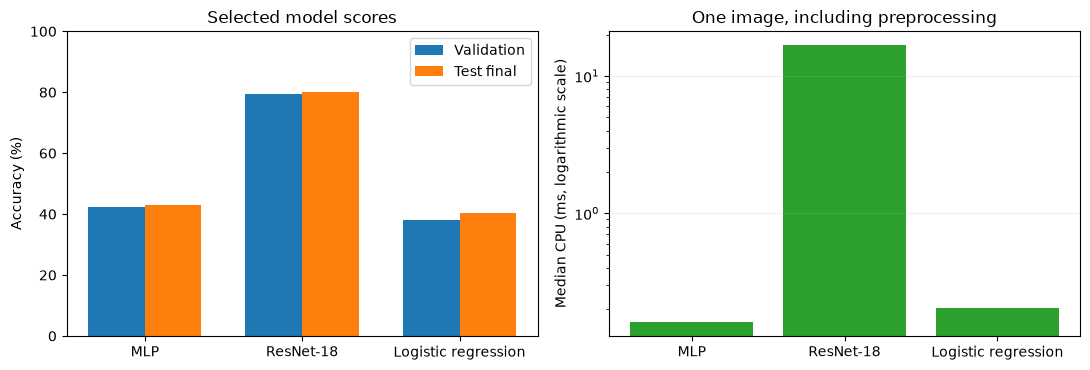

In [45]:
labels = ["MLP", "ResNet-18", "Logistic regression"]
x = np.arange(len(final_comparison))
fig, (ax_score, ax_time) = plt.subplots(1, 2, figsize=(11, 3.8))
ax_score.bar(x - 0.18, 100 * final_comparison["validation_accuracy"], width=0.36, label="Validation")
ax_score.bar(x + 0.18, 100 * final_comparison["test_accuracy"], width=0.36, label="Test final")
ax_score.set(xticks=x, xticklabels=labels, ylabel="Accuracy (%)", ylim=(0, 100), title="Selected model scores")
ax_score.legend()
ax_time.bar(x, final_comparison["with_preprocessing_median_ms"], color="tab:green")
ax_time.set(xticks=x, xticklabels=labels, ylabel="Median CPU (ms, logarithmic scale)",
            title="One image, including preprocessing", yscale="log")
ax_time.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


### Final test errors

We read the matrices saved during the single evaluation. Each row represents 45 paintings of one style.
Diagonal entries are correct predictions. These errors describe the final result, not a basis for further tuning.


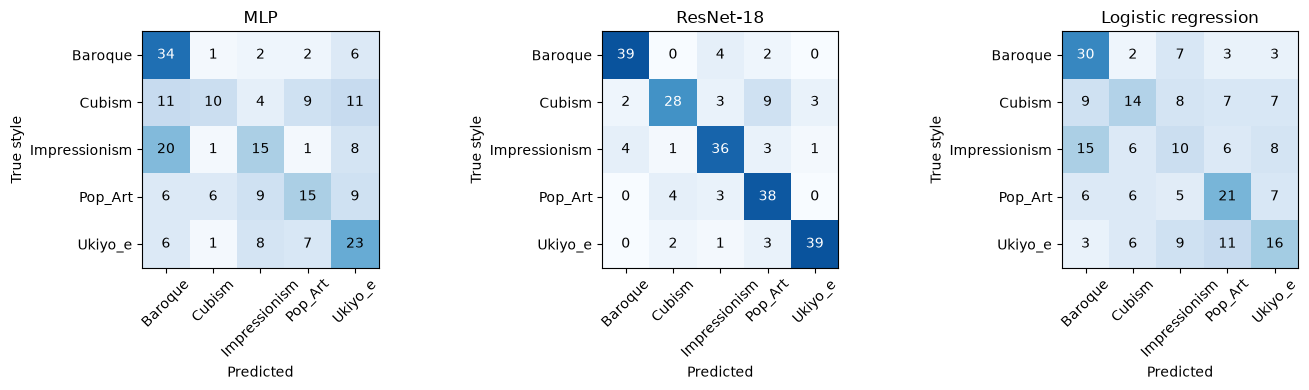

,MLP,ResNet-18,Logistic regression
Style,,,
Baroque,75.6,86.7,66.7
Cubism,22.2,62.2,31.1
Impressionism,33.3,80.0,22.2
Pop_Art,33.3,84.4,46.7
Ukiyo_e,51.1,86.7,35.6


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
recalls = {}
for ax, family, title in zip(axes, final_comparison.index, labels):
    matrix = pd.read_csv(FINAL_DIR / f"test_confusion_{family}.csv", index_col=0)
    ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=45)
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            value = int(matrix.iloc[row, column])
            ax.text(column, row, str(value), ha="center", va="center", color="white" if value > 23 else "black")
    ax.set(xticks=range(5), yticks=range(5), xticklabels=class_names, yticklabels=class_names,
           title=title, xlabel="Predicted", ylabel="True style")
    ax.tick_params(axis="x", labelrotation=45)
    recalls[title] = 100 * matrix.values.diagonal() / matrix.sum(axis=1).values
plt.tight_layout()
plt.show()
pd.DataFrame(recalls, index=class_names).rename_axis("Style").round(1)


### Which model should the museum use?

Among the three candidates selected before the test, the **fine-tuned ResNet is most accurate: 80.0%**,
or 180 of 225 paintings, with a macro F1 of 79.9%.
The MLP achieves 43.1% (97 paintings) and logistic regression 40.4% (91 paintings).
The MLP gets only six more correct answers than the classical model; that small difference alone does not justify
its 12.13 MiB file compared with 0.47 MiB for logistic regression.

On this ARM machine with eight logical CPUs and one thread, the full ResNet takes **16.74 ms** median
and **18.63 ms at the 95th percentile**, including image preprocessing. Its checkpoint is **42.71 MiB**.
Both pixel-based models take less than a millisecond. Logistic regression is not faster than the MLP
with these library calls; at this scale, call overhead and numerical types also matter.

For a guide pilot, we favor the **fine-tuned ResNet**: its recognition advantage is much clearer than the MLP's
and its measured CPU cost appears compatible with interactive use on this machine. This must still be checked
on museum hardware. The linear model remains a very compact option, but recognizing around four paintings in ten
would be a significant limitation for the intended service.

ResNet still makes 45 errors. Cubism is its hardest test style: 28 of 45 images are recognized and nine are
mistaken for Pop Art. The indicative 95% Wilson interval for accuracy is 74.3% to 84.7%; it does not account
for possible dependencies between paintings by the same artist. These results support a prototype,
not production validation on visitor photos.


## 10. Limitations and summary

The eight technical steps are complete: data prepared, MLP diagnosed and regularized, ResNet head trained,
last block fine-tuned, classical model compared and final test evaluated.
Curves, parameter searches, matrices and CPU measurements are saved in `outputs/`.

Validation informed several choices using one seed. Test scores cover 225 images from a small cropped WikiArt subset.
Artists are poorly documented and not separated between splits. Visitor photographs also introduce framing,
reflections and lighting not represented in these files. Performance must therefore be validated on museum photos
and target hardware before deployment.

The 10-minute oral presentation and five minutes of questions remain to be prepared.
Natural-language artwork search remains a future direction.


## 11. Further work: three more baselines

These experiments were added after the final evaluation of the three previous models. We therefore compare them
**only on validation**, without reopening the test for their predictions. They explore other trade-offs for the museum;
they do not retroactively replace the final comparison's candidates.

- **A small CNN trained from scratch**: three convolutions exploit neighboring pixels, using the MLP's 64 × 64 images.
- **HOG + color histograms + linear SVM**: edge and color features computed without a pretrained network,
  with normalization fitted on training only. `C` is selected on validation.
- **Pretrained MobileNetV3-Small**: a compact network with only a new linear head trained,
  seeking a lighter alternative to ResNet.

We keep seed 42 and the same manifest. The CNN uses dropout 0.3 and weight decay 0.0001;
MobileNet follows the ResNet head protocol (learning rate 0.001, at most 60 epochs, patience 10).
[HOG features](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html)
and [torchvision MobileNet](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html)
are described in their documentation.


In [47]:
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small
import skimage

ADDITIONAL_DIR = ROOT / "outputs/additional_models"
CNN_CONFIG = {"name": "tiny_cnn", "seed": SEED, "epochs": 40, "learning_rate": 1e-3,
              "weight_decay": 1e-4, "patience": 8, "batch_size": 64,
              "input_size": 64, "dropout": 0.3, "normalization_mean": list(NORMALIZE_MEAN),
              "normalization_std": list(NORMALIZE_STD)}
MOBILE_CONFIG = {"name": "mobilenet_v3_small_head", "seed": SEED, "epochs": 60,
                 "learning_rate": 1e-3, "weight_decay": 1e-4, "patience": 10,
                 "batch_size": 64, "extraction_batch_size": 32,
                 "weights": "MobileNet_V3_Small_Weights.IMAGENET1K_V1", "trainable_layers": ["classifier"]}
HOG_CONFIG = {"name": "hog_svm", "seed": SEED, "input_size": 64, "orientations": 9,
              "pixels_per_cell": [8, 8], "cells_per_block": [2, 2], "color_bins_per_channel": 16,
              "C_values": [0.000001, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
              "selection": "validation accuracy, then macro F1, then smaller C",
              "scaling": "StandardScaler fitted on train only"}

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 4 * 4, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


def run_tiny_cnn():
    set_seed(SEED)
    experiment_device = choose_device(MLP_CONFIG.device)
    experiment_loaders, classes, _, _ = read_training_rows(DATA_DIR, MANIFEST_PATH, SEED, 0, CNN_CONFIG["batch_size"])
    model = TinyCNN(len(classes)).to(experiment_device)
    print("Small CNN:", sum(p.numel() for p in model.parameters()), "parameters", flush=True)
    records, result = fit_experiment(
        model, experiment_loaders, epochs=CNN_CONFIG["epochs"], learning_rate=CNN_CONFIG["learning_rate"],
        weight_decay=CNN_CONFIG["weight_decay"], patience=CNN_CONFIG["patience"], seed=SEED,
        experiment_device=experiment_device,
    )
    matrix = validation_confusion(model, experiment_loaders["validation"], len(classes), experiment_device)
    result.update(model="Small CNN trained from scratch", device=str(experiment_device),
                  parameter_count=sum(p.numel() for p in model.parameters()))
    save_experiment(model, records, result, ADDITIONAL_DIR / "tiny_cnn", CNN_CONFIG, classes, matrix)
    print(f"Small CNN: validation {result['best_validation_accuracy']:.1%}", flush=True)


def hog_color_features(image):
    image = image.convert("RGB").resize((64, 64), Image.Resampling.BILINEAR)
    rgb = np.asarray(image, dtype=np.float32) / 255.0
    gray = np.asarray(image.convert("L"), dtype=np.float32) / 255.0
    edges = hog(gray, orientations=HOG_CONFIG["orientations"], pixels_per_cell=(8, 8),
                cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)
    colors = [np.histogram(rgb[:, :, channel], bins=16, range=(0, 1))[0] / (64 * 64) for channel in range(3)]
    return np.concatenate([edges, *colors]).astype(np.float64)


def hog_dataset(records):
    features, labels = [], []
    for record in records:
        with Image.open(DATA_DIR / record["relative_path"]) as image:
            features.append(hog_color_features(image))
        labels.append(int(record["label_idx"]))
    return np.stack(features), np.asarray(labels)


def run_hog_svm():
    folder = ADDITIONAL_DIR / "hog_svm"
    folder.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    x_train, y_train = hog_dataset(loaders["train"].dataset.records)
    x_val, y_val = hog_dataset(loaders["validation"].dataset.records)
    feature_seconds = time.perf_counter() - started
    best_key, best_model, records = (-1.0, -1.0), None, []
    with threadpool_limits(limits=1):
        for c_value in HOG_CONFIG["C_values"]:
            fit_started = time.perf_counter()
            for maximum in (10000, 50000):
                classifier = make_pipeline(StandardScaler(), LinearSVC(C=c_value, random_state=SEED, max_iter=maximum))
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    classifier.fit(x_train, y_train)
                converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
                if converged:
                    break
            if not converged:
                raise RuntimeError(f"SVM did not converge for C={c_value}.")
            train_predictions, val_predictions = classifier.predict(x_train), classifier.predict(x_val)
            train_accuracy, val_accuracy = accuracy_score(y_train, train_predictions), accuracy_score(y_val, val_predictions)
            macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0)
            record = {"C": c_value, "train_accuracy": train_accuracy, "validation_accuracy": val_accuracy,
                      "validation_macro_f1": macro_f1, "converged": converged,
                      "iterations": int(classifier.named_steps["linearsvc"].n_iter_),
                      "fit_seconds": time.perf_counter() - fit_started}
            records.append(record)
            print(f"HOG + SVM C={c_value:g} : train {train_accuracy:.1%}, validation {val_accuracy:.1%}", flush=True)
            if (val_accuracy, macro_f1) > best_key:
                best_key, best_model, best_record = (val_accuracy, macro_f1), classifier, record.copy()
    (folder / "checkpoints").mkdir(exist_ok=True)
    checkpoint = folder / "checkpoints/best.joblib"
    joblib.dump(best_model, checkpoint, compress=0)
    matrix = confusion_matrix(y_val, best_model.predict(x_val), labels=np.arange(len(class_names)))
    pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis("true_style").to_csv(folder / "validation_confusion.csv")
    pd.DataFrame(records).to_csv(folder / "validation_search.csv", index=False)
    svm = best_model.named_steps["linearsvc"]
    result = {"model": "Linear SVM on HOG + RGB histograms", "config": HOG_CONFIG, "best_C": best_record["C"],
              "best_validation_accuracy": best_record["validation_accuracy"], "validation_macro_f1": best_record["validation_macro_f1"],
              "train_accuracy_at_best_epoch": best_record["train_accuracy"], "test_evaluated": False,
              "parameter_count": int(svm.coef_.size + svm.intercept_.size), "feature_size": int(x_train.shape[1]),
              "feature_extraction_seconds": feature_seconds, "training_seconds": time.perf_counter() - started - feature_seconds,
              "converged": True, "checkpoint": checkpoint.relative_to(ROOT).as_posix(), "class_names": class_names,
              "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
              "versions": {"sklearn": sklearn.__version__, "skimage": skimage.__version__, "numpy": np.__version__}}
    (folder / "validation_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print(f"Selected SVM: C={best_record['C']:g}, validation {best_record['validation_accuracy']:.1%}", flush=True)


def run_mobilenet_head():
    set_seed(SEED)
    experiment_device = choose_device(MLP_CONFIG.device)
    weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = mobilenet_v3_small(weights=weights)
    model.requires_grad_(False)
    feature_size = model.classifier[0].in_features
    model.classifier = nn.Linear(feature_size, len(class_names))
    model.to(experiment_device).eval()
    include_backbone = lambda name: not name.startswith("classifier.")
    before = state_digest(model, include_backbone)
    extractor = nn.Sequential(model.features, model.avgpool, nn.Flatten()).eval()
    feature_datasets = {}
    started = time.perf_counter()
    for split in ("train", "validation"):
        dataset = ManifestImageDataset(DATA_DIR, loaders[split].dataset.records, weights.transforms())
        print("MobileNet : extraction", split, flush=True)
        feature_datasets[split] = extract_features(extractor, dataset, MOBILE_CONFIG["extraction_batch_size"], experiment_device)
    feature_seconds = time.perf_counter() - started
    generator = torch.Generator().manual_seed(SEED)
    feature_loaders = {
        split: DataLoader(dataset, batch_size=MOBILE_CONFIG["batch_size"], shuffle=(split == "train"),
                          generator=generator if split == "train" else None)
        for split, dataset in feature_datasets.items()
    }
    records, result = fit_experiment(
        model.classifier, feature_loaders, epochs=MOBILE_CONFIG["epochs"], learning_rate=MOBILE_CONFIG["learning_rate"],
        weight_decay=MOBILE_CONFIG["weight_decay"], patience=MOBILE_CONFIG["patience"], seed=SEED,
        experiment_device=experiment_device,
    )
    after = state_digest(model, include_backbone)
    assert before == after
    matrix = validation_confusion(model.classifier, feature_loaders["validation"], len(class_names), experiment_device)
    result.update(model="MobileNetV3-Small frozen backbone + linear head", device=str(experiment_device),
                  parameter_count=sum(p.numel() for p in model.parameters()),
                  trainable_parameter_count=sum(p.numel() for p in model.parameters() if p.requires_grad),
                  feature_size=feature_size, feature_extraction_seconds=feature_seconds,
                  backbone_sha256_before=before, backbone_sha256_after=after, backbone_unchanged=True)
    save_experiment(model, records, result, ADDITIONAL_DIR / "mobilenet_v3_small_head", MOBILE_CONFIG, class_names, matrix)
    print(f"MobileNet : validation {result['best_validation_accuracy']:.1%}", flush=True)

if RUN_ADDITIONAL_MODELS:
    run_tiny_cnn()
    run_hog_svm()
    run_mobilenet_head()


In [48]:
additional_names = ["tiny_cnn", "hog_svm", "mobilenet_v3_small_head"]
additional_results = {}
for name in additional_names:
    path = ADDITIONAL_DIR / name / "validation_summary.json"
    if not path.is_file():
        raise FileNotFoundError("Additional experiments missing: set RUN_ADDITIONAL_MODELS = True.")
    additional_results[name] = json.loads(path.read_text(encoding="utf-8"))

pd.DataFrame([
    {"Model": name, "Train (%)": 100 * result["train_accuracy_at_best_epoch"],
     "Validation (%)": 100 * result["best_validation_accuracy"], "Parameters": result["parameter_count"],
     "Test evaluated": result["test_evaluated"]}
    for name, result in additional_results.items()
]).set_index("Model").round(2)


,Train (%),Validation (%),Parameters,Test evaluated
Model,,,,
tiny_cnn,62.48,53.33,155429,False
hog_svm,79.71,52.44,9065,False
mobilenet_v3_small_head,87.71,76.00,929893,False


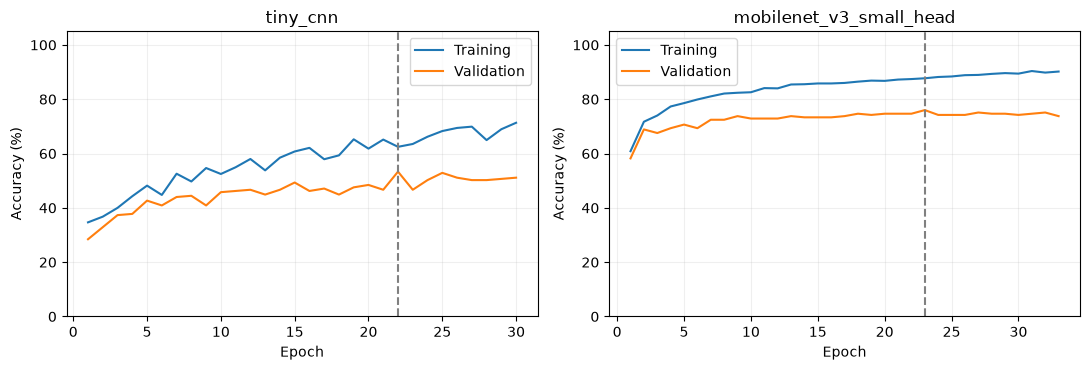

,C,train_accuracy,validation_accuracy,validation_macro_f1,converged
0,1e-06,0.5114,0.4578,0.4619,True
1,1e-05,0.5981,0.4978,0.4997,True
2,0.0001,0.7971,0.5244,0.5235,True
3,0.001,0.9705,0.3956,0.3921,True
4,0.01,1.0000,0.3644,0.3696,True
5,0.1,1.0000,0.3689,0.3735,True
6,1,1.0000,0.3689,0.3735,True
7,10,1.0000,0.3689,0.3735,True


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, ("tiny_cnn", "mobilenet_v3_small_head")):
    run_history = pd.read_csv(ADDITIONAL_DIR / name / "training_history.csv")
    ax.plot(run_history["epoch"], 100 * run_history["train_accuracy"], label="Training")
    ax.plot(run_history["epoch"], 100 * run_history["validation_accuracy"], label="Validation")
    ax.axvline(additional_results[name]["best_epoch"], color="gray", linestyle="--")
    ax.set(title=name, xlabel="Epoch", ylabel="Accuracy (%)", ylim=(0, 105))
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

hog_search = pd.read_csv(ADDITIONAL_DIR / "hog_svm/validation_search.csv")
hog_table = hog_search[["C", "train_accuracy", "validation_accuracy", "validation_macro_f1", "converged"]].copy()
hog_table["C"] = hog_table["C"].map(lambda value: f"{value:g}")
hog_table.round(4)


### Accuracy / CPU cost trade-off

We reuse the previous comparison's protocol: one thread, batch size 1, ten warm-up passes and 100 measurements
on the same ten validation images. HOG and histograms are included in preprocessing time.
The full MobileNet backbone runs for each image. These measurements were made in a separate session;
the times for the first three models are from the previous benchmark.


In [50]:
def load_additional_models():
    models = {}
    for name, result in additional_results.items():
        checkpoint_path = ROOT / result["checkpoint"]
        if name == "hog_svm":
            models[name] = joblib.load(checkpoint_path)
            continue
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if name == "tiny_cnn":
            model = TinyCNN(len(class_names))
        else:
            model = mobilenet_v3_small(weights=None)
            model.classifier = nn.Linear(model.classifier[0].in_features, len(class_names))
        model.load_state_dict(checkpoint["model_state_dict"])
        models[name] = model.cpu().eval().requires_grad_(False)
    return models


def benchmark_additional_models():
    models = load_additional_models()
    sample = random.Random(SEED).sample(loaders["validation"].dataset.records, BENCHMARK_CONFIG["validation_images"])
    images = []
    for record in sample:
        with Image.open(DATA_DIR / record["relative_path"]) as image:
            images.append(image.convert("RGB"))
    pixels = final_preprocessors()["pixels"]
    mobile_preprocess = MobileNet_V3_Small_Weights.IMAGENET1K_V1.transforms()
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(1)
    records = []
    try:
        with threadpool_limits(limits=1), torch.inference_mode():
            for name, model in models.items():
                def prepare(image):
                    if name == "hog_svm":
                        return hog_color_features(image).reshape(1, -1)
                    return (pixels if name == "tiny_cnn" else mobile_preprocess)(image).unsqueeze(0)

                def predict(values):
                    return model.predict(values) if name == "hog_svm" else model(values).argmax(dim=1)

                inputs = [prepare(image) for image in images]
                for i in range(BENCHMARK_CONFIG["warmup"]):
                    predict(inputs[i % len(inputs)])
                timings = {}
                for mode in ("model_only", "with_preprocessing"):
                    elapsed = []
                    for i in range(BENCHMARK_CONFIG["repeats"]):
                        index = i % len(images)
                        started = time.perf_counter_ns()
                        predict(inputs[index] if mode == "model_only" else prepare(images[index]))
                        elapsed.append((time.perf_counter_ns() - started) / 1e6)
                    timings[f"{mode}_median_ms"] = float(np.median(elapsed))
                    timings[f"{mode}_p95_ms"] = float(np.percentile(elapsed, 95))
                result = additional_results[name]
                size = (ROOT / result["checkpoint"]).stat().st_size
                records.append({"family": name, "variant": name, **timings,
                    "validation_accuracy": result["best_validation_accuracy"], "parameter_count": result["parameter_count"],
                    "checkpoint_bytes": size, "checkpoint_mib": size / (1024 ** 2), "test_evaluated": False})
    finally:
        torch.set_num_threads(previous_threads)
    pd.DataFrame(records).to_csv(ADDITIONAL_DIR / "cpu_benchmark.csv", index=False)
    protocol = {**BENCHMARK_CONFIG, "machine": platform.machine(), "processor": platform.processor(),
                "logical_cpus": os.cpu_count(), "torch": torch.__version__, "sklearn": sklearn.__version__,
                "skimage": skimage.__version__, "test_images_used": 0,
                "note": "same timing protocol as the original comparison, measured in a separate run"}
    (ADDITIONAL_DIR / "cpu_benchmark_protocol.json").write_text(json.dumps(protocol, indent=2) + "\n", encoding="utf-8")

if RUN_ADDITIONAL_BENCHMARK:
    benchmark_additional_models()

additional_cpu = pd.read_csv(ADDITIONAL_DIR / "cpu_benchmark.csv").set_index("family")
reference_cpu = final_comparison[["variant", "validation_accuracy", "with_preprocessing_median_ms", "checkpoint_mib"]]
all_validation_models = pd.concat([
    reference_cpu,
    additional_cpu[["variant", "validation_accuracy", "with_preprocessing_median_ms", "checkpoint_mib"]],
])
validation_comparison = all_validation_models.copy()
validation_comparison["validation_accuracy"] *= 100
validation_comparison.rename(columns={"variant": "Variant", "validation_accuracy": "Validation (%)",
    "with_preprocessing_median_ms": "CPU with preprocessing (ms)", "checkpoint_mib": "Size (MiB)"}).round(3)


,Variant,Validation (%),CPU with preprocessing (ms),Size (MiB)
family,,,,
mlp,dropout,42.222,0.161,12.132
resnet,layer4,79.556,16.742,42.711
logistic,C=0.001,38.222,0.204,0.470
tiny_cnn,tiny_cnn,53.333,0.417,0.597
hog_svm,hog_svm,52.444,0.738,0.112
mobilenet_v3_small_head,mobilenet_v3_small_head,76.000,11.650,3.653


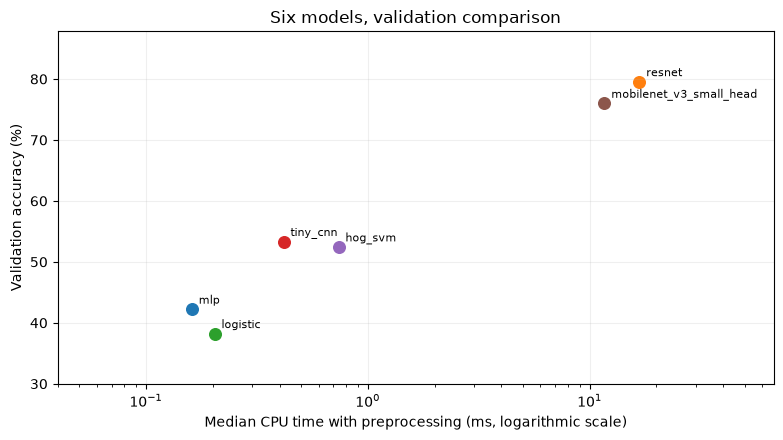

In [51]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, row in all_validation_models.iterrows():
    ax.scatter(row["with_preprocessing_median_ms"], 100 * row["validation_accuracy"], s=70)
    ax.annotate(name, (row["with_preprocessing_median_ms"], 100 * row["validation_accuracy"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set(xscale="log", xlabel="Median CPU time with preprocessing (ms, logarithmic scale)",
       ylabel="Validation accuracy (%)", title="Six models, validation comparison")
ax.margins(x=0.3, y=0.2)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### What the three experiments add

The **small CNN reaches 53.3% validation accuracy**, versus 42.2% for the dropout MLP,
with 155,429 parameters instead of 3,179,525. It selects epoch 22 and stops at epoch 30.
Its training score at the selected checkpoint is 62.5%: it memorizes training examples much less than the MLP.
Convolutions provide a better starting point here, though capacity and regularization also differ.

The **HOG and color SVM reaches 52.4%**, with C = 0.0001. The grid was extended to smaller C values
because the first best setting was at the boundary. Edges and histograms therefore add much to the classical
raw-pixel model (38.2%). The CNN exceeds it by only two images out of 225, too little to distinguish them reliably.
The SVM takes **0.11 MiB** and **0.74 ms** including feature computation; the CNN takes 0.60 MiB and 0.42 ms.
HOG computation thus contributes more to response time than linear prediction.

**MobileNetV3-Small reaches 76.0%** at epoch 23, with 2,885 trainable and 929,893 total parameters.
Its pretrained backbone remained unchanged. Its score is within one image of the head-only ResNet (75.6%)
and eight images of the fine-tuned ResNet (79.6%). Its checkpoint is **3.65 MiB**, almost twelve times
smaller than ResNet's; CPU latency is **11.65 ms**, approximately 30% lower in these measurements.
A much smaller network is therefore not necessarily proportionally faster.

These results make **MobileNet an interesting candidate for a future memory-constrained pilot**,
and HOG + SVM a stronger classical baseline than raw pixels. Fine-tuned ResNet remains the most accurate
on validation among these six experiments. The new models have no test scores: they were added after the initial
final evaluation. Confirming a new deployment choice requires an independent evaluation set and kiosk measurements.


## 12. An independent test for the new models

The initial test was already used to compare the first three models. To evaluate the new experiments fairly,
we reserve 100 new images per style from the same pinned WikiArt revision. The plan excludes identifiers already
in the first subset and checks for exact duplicates using SHA-256. Selection uses seed 20261030 and a cap of
20 images per named artist.

The manifest and its hash are sealed before the new training runs. We do not display these images or their scores
until models are selected on validation. Download is enabled once with `CREATE_FRESH_TEST = True`.
Images remain in `data/`, ignored by Git; the test manifest is kept in `manifests/`.


In [52]:
from copy import deepcopy
import shutil

FRESH_TEST_DIR = ROOT / "data/wikiart_style5_fresh_test"
FRESH_TEST_MANIFEST = ROOT / "manifests/wikiart_style5_fresh_test.csv"
FRESH_TEST_CONFIG = {
    "repo": REPO, "revision": REVISION, "seed": 20261034, "per_class": 100,
    "classes": ["Baroque", "Cubism", "Impressionism", "Pop_Art", "Ukiyo_e"],
    "strategy": "spread", "max_per_artist": 20, "size": 128, "crop": True,
    "purpose": "independent final test; select no model or hyperparameter using it",
}


def existing_content_hashes():
    metadata = list(csv.DictReader((DATA_DIR / "metadata.csv").open(encoding="utf-8", newline="")))
    ids = {row["id"] for row in metadata}
    hashes = {hashlib.sha256((DATA_DIR / row["path"]).read_bytes()).hexdigest() for row in metadata}
    artists = {row.get("artist", UNKNOWN_ARTIST) for row in metadata if row.get("artist", UNKNOWN_ARTIST) != UNKNOWN_ARTIST}
    return ids, hashes, artists


def create_fresh_test():
    if FRESH_TEST_MANIFEST.exists():
        raise FileExistsError("The independent test set already exists; do not replace it after experiments have started.")
    cache = default_index_path(FRESH_TEST_CONFIG["revision"])
    index = load_label_index(FRESH_TEST_CONFIG["revision"], cache, retries=3)
    classes = FRESH_TEST_CONFIG["classes"]
    class_ids = resolve_classes(classes, index["names"]["style"])
    existing_ids, old_hashes, train_artists = existing_content_hashes()
    index_without_seen_images = deepcopy(index)
    banned_ids = set(existing_ids)

    for attempt in range(20):
        planned_index = deepcopy(index_without_seen_images)
        for shard_id, shard in enumerate(planned_index["shards"]):
            for row_id_in_shard, value in enumerate(shard["style"]):
                if row_id(shard_id, row_id_in_shard) in banned_ids:
                    shard["style"][row_id_in_shard] = -999999
        plan, remaining = make_plan(
            planned_index, "style", class_ids, FRESH_TEST_CONFIG["per_class"],
            FRESH_TEST_CONFIG["max_per_artist"], FRESH_TEST_CONFIG["strategy"],
            FRESH_TEST_CONFIG["seed"] + attempt,
        )
        if any(remaining.values()):
            raise RuntimeError(f"Incomplete independent selection: {remaining}")
        print_plan(plan, remaining, index, "style", class_ids, FRESH_TEST_CONFIG["per_class"])
        named_by_style = Counter()
        for shard_id, selected_rows in plan.items():
            for row_id_in_shard in selected_rows:
                artist_id = index["shards"][shard_id]["artist"][row_id_in_shard]
                artist_name = index["names"]["artist"][artist_id]
                style_id = index["shards"][shard_id]["style"][row_id_in_shard]
                if artist_name != UNKNOWN_ARTIST:
                    named_by_style[index["names"]["style"][style_id]] += 1
        if any(named_by_style[name] < 10 for name in classes):
            print("Draw rejected: fewer than ten identified artists in a style; retrying deterministically.")
            continue
        print("Planned identified artists by style:", dict(sorted(named_by_style.items())))
        if FRESH_TEST_DIR.exists():
            shutil.rmtree(FRESH_TEST_DIR)
        class_names = {class_id: index["names"]["style"][class_id] for class_id in class_ids}
        for name in class_names.values():
            (FRESH_TEST_DIR / name).mkdir(parents=True, exist_ok=True)
        args = SimpleNamespace(
            out=FRESH_TEST_DIR, size=FRESH_TEST_CONFIG["size"], no_crop=False, quality=90,
            revision=FRESH_TEST_CONFIG["revision"], retries=3, label="style",
            per_class=FRESH_TEST_CONFIG["per_class"], seed=FRESH_TEST_CONFIG["seed"] + attempt,
            strategy=FRESH_TEST_CONFIG["strategy"], max_per_artist=FRESH_TEST_CONFIG["max_per_artist"],
        )
        os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "1800")
        sizes = download(plan, index, "style", class_names, args, previous_sizes(FRESH_TEST_DIR))
        image_metadata = write_metadata(plan, index, "style", class_ids, class_names, args, sizes)
        rows = list(csv.DictReader((FRESH_TEST_DIR / "metadata.csv").open(encoding="utf-8", newline="")))
        by_hash = defaultdict(list)
        for row in rows:
            digest = hashlib.sha256((FRESH_TEST_DIR / row["path"]).read_bytes()).hexdigest()
            by_hash[digest].append(row)
        collisions = {row["id"] for digest, group in by_hash.items()
                      if digest in old_hashes or len(group) > 1 for row in group}
        replacement_number = 0
        while collisions:
            replacement_number += 1
            if replacement_number > 20:
                raise RuntimeError("Too many content duplicates; the test was not sealed.")
            print(f"{len(collisions)} duplicate image(s); replacing within the same shard plan.")
            replacements = []
            selected_ids = {row_id(shard_id, row_number)
                            for shard_id, selected_rows in plan.items() for row_number in selected_rows}
            named_counts = Counter()
            artist_counts = Counter()
            for shard_id, selected_rows in plan.items():
                kept = []
                for row_number in selected_rows:
                    identifier = row_id(shard_id, row_number)
                    style_id = index["shards"][shard_id]["style"][row_number]
                    artist_id = index["shards"][shard_id]["artist"][row_number]
                    artist_name = index["names"]["artist"][artist_id]
                    if identifier in collisions:
                        replacements.append(style_id)
                        selected_ids.discard(identifier)
                        duplicate_file = FRESH_TEST_DIR / class_names[style_id] / f"{identifier}.jpg"
                        if duplicate_file.exists():
                            duplicate_file.unlink()
                    else:
                        kept.append(row_number)
                        if artist_name != UNKNOWN_ARTIST:
                            named_counts[index["names"]["style"][style_id]] += 1
                            artist_counts[artist_name] += 1
                plan[shard_id] = kept
            for style_id in replacements:
                selected_shards = list(plan)
                all_shards = selected_shards + [s for s in range(len(index["shards"])) if s not in plan]
                candidates = []
                for shard_id in all_shards:
                    for row_number, candidate_style in enumerate(index["shards"][shard_id]["style"]):
                        identifier = row_id(shard_id, row_number)
                        if candidate_style != style_id or identifier in banned_ids or identifier in selected_ids:
                            continue
                        artist_id = index["shards"][shard_id]["artist"][row_number]
                        artist_name = index["names"]["artist"][artist_id]
                        style_name = index["names"]["style"][style_id]
                        if artist_name != UNKNOWN_ARTIST:
                            if artist_counts[artist_name] >= FRESH_TEST_CONFIG["max_per_artist"]:
                                continue
                        elif named_counts[style_name] < 10:
                            continue
                        candidates.append((shard_id, row_number, artist_name))
                    if candidates:
                        break
                if not candidates:
                    raise RuntimeError(f"No replacement available for {index['names']['style'][style_id]}.")
                random.Random(args.seed + replacement_number + style_id).shuffle(candidates)
                shard_id, row_number, artist_name = candidates[0]
                plan.setdefault(shard_id, []).append(row_number)
                selected_ids.add(row_id(shard_id, row_number))
                if artist_name != UNKNOWN_ARTIST:
                    artist_counts[artist_name] += 1
                    named_counts[index["names"]["style"][style_id]] += 1
            sizes = download(plan, index, "style", class_names, args, previous_sizes(FRESH_TEST_DIR))
            image_metadata = write_metadata(plan, index, "style", class_ids, class_names, args, sizes)
            rows = list(csv.DictReader((FRESH_TEST_DIR / "metadata.csv").open(encoding="utf-8", newline="")))
            by_hash = defaultdict(list)
            for row in rows:
                digest = hashlib.sha256((FRESH_TEST_DIR / row["path"]).read_bytes()).hexdigest()
                by_hash[digest].append(row)
            collisions = {row["id"] for digest, group in by_hash.items()
                          if digest in old_hashes or len(group) > 1 for row in group}
            banned_ids.update(collisions)
        counts = Counter(row["label"] for row in rows)
        assert counts == Counter({name: FRESH_TEST_CONFIG["per_class"] for name in classes})
        manifest_rows = []
        for row in rows:
            manifest_rows.append({
                "relative_path": (Path("data") / FRESH_TEST_DIR.name / row["path"]).as_posix(),
                "label": row["label"], "label_idx": int(row["label_idx"]), "split": "test",
                "seed": args.seed, "artist": row.get("artist", UNKNOWN_ARTIST), "id": row["id"],
            })
        FRESH_TEST_MANIFEST.parent.mkdir(parents=True, exist_ok=True)
        with FRESH_TEST_MANIFEST.open("x", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(manifest_rows[0]))
            writer.writeheader()
            writer.writerows(sorted(manifest_rows, key=lambda row: (row["label_idx"], row["relative_path"])))
        lock = {
            **FRESH_TEST_CONFIG, "selected_seed": args.seed,
            "images": len(manifest_rows), "class_counts": dict(sorted(counts.items())),
            "excluded_existing_ids": len(existing_ids), "duplicate_content_collisions": 0,
            "overlapping_named_artists": len(train_artists & {row.get("artist", UNKNOWN_ARTIST) for row in rows}),
            "images_with_named_artist_by_style": dict(sorted(Counter(row["label"] for row in rows if row.get("artist", UNKNOWN_ARTIST) != UNKNOWN_ARTIST).items())),
            "manifest": FRESH_TEST_MANIFEST.relative_to(ROOT).as_posix(),
            "manifest_sha256": hashlib.sha256(FRESH_TEST_MANIFEST.read_bytes()).hexdigest(),
            "test_model_predictions": 0,
        }
        lock_path = ROOT / "outputs/independent_test/holdout_lock.json"
        lock_path.parent.mkdir(parents=True, exist_ok=True)
        with lock_path.open("x", encoding="utf-8") as stream:
            json.dump(lock, stream, indent=2, ensure_ascii=False)
            stream.write("\n")
        print("Independent set sealed:", len(manifest_rows), "images; no duplicate hashes.")
        print("Identified artists by style:", lock["images_with_named_artist_by_style"])
        print("Named artists shared between subsets:", lock["overlapping_named_artists"])
        return lock
    raise RuntimeError("Unable to build a duplicate-free test after 20 deterministic plans.")

if CREATE_FRESH_TEST:
    create_fresh_test()

fresh_test_lock_path = ROOT / "outputs/independent_test/holdout_lock.json"
if not fresh_test_lock_path.is_file():
    raise FileNotFoundError("Independent test missing: set CREATE_FRESH_TEST = True before the experiments.")
fresh_test_lock = json.loads(fresh_test_lock_path.read_text(encoding="utf-8"))
assert fresh_test_lock["test_model_predictions"] in (0, 1)
assert hashlib.sha256(FRESH_TEST_MANIFEST.read_bytes()).hexdigest() == fresh_test_lock["manifest_sha256"]
if fresh_test_lock["test_model_predictions"] == 1:
    assert fresh_test_lock.get("evaluation_status") == "complete"
    evaluation_path = ROOT / "outputs/independent_test/evaluation.json"
    assert evaluation_path.is_file()
    assert hashlib.sha256(evaluation_path.read_bytes()).hexdigest() == fresh_test_lock["evaluation_result_sha256"]
print(f"Independent test ready: {fresh_test_lock['images']} images; status {fresh_test_lock.get('evaluation_status', 'sealed')}.")


Independent test ready: 500 images; status complete.


## 13. MobileNet and EfficientNet: three seeds, with and without fine-tuning

We compare five recipes on the same training and validation images, using seeds 42, 43 and 44: MobileNetV3-Small with its head alone, its last three blocks fine-tuned, and then those blocks with light augmentations; EfficientNet-B0 with its head alone, then its last two blocks fine-tuned with those augmentations.

The seed 42 head-only MobileNet checkpoint is the already trained experiment; the other two seeds complete the comparison. Unfrozen blocks use a learning rate of `3e-5`, versus `3e-4` for the head. The frozen prefix and BatchNorm statistics remain fixed. Runs are selected by mean validation accuracy across three seeds.


In [53]:
from torchvision.models import (
    EfficientNet_B0_Weights, MobileNet_V3_Small_Weights, efficientnet_b0, mobilenet_v3_small,
)
from torchvision.transforms import InterpolationMode
import gc

TRANSFER_DIR = ROOT / "outputs/transfer_study"
TRANSFER_SEEDS = [42, 43, 44]
TRANSFER_RECIPES = [
    {"architecture": "mobilenet_v3_small", "variant": "head", "layer_start": 13, "augment": False},
    {"architecture": "mobilenet_v3_small", "variant": "last3", "layer_start": 10, "augment": False},
    {"architecture": "mobilenet_v3_small", "variant": "last3_aug", "layer_start": 10, "augment": True},
    {"architecture": "efficientnet_b0", "variant": "head", "layer_start": 9, "augment": False},
    {"architecture": "efficientnet_b0", "variant": "last2_aug", "layer_start": 6, "augment": True},
]

class PrefixAndTail(nn.Module):
    """A pretrained feature extractor with a frozen prefix and a trainable suffix."""
    def __init__(self, feature_layers, layer_start, avgpool, classifier):
        super().__init__()
        self.prefix = nn.Sequential(*feature_layers[:layer_start])
        self.tail = nn.Sequential(*feature_layers[layer_start:], avgpool, nn.Flatten())
        self.classifier = classifier
        self.layer_start = layer_start
        self.prefix.requires_grad_(False)

    def forward(self, images):
        with torch.no_grad():
            features = self.prefix(images)
        return self.classifier(self.tail(features))

    def train(self, mode=True):
        super().train(mode)
        self.prefix.eval()
        # Let convolution weights adapt while keeping small-batch running statistics fixed.
        for module in self.modules():
            if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
                module.eval()
        return self


def new_pretrained_model(architecture, seed):
    set_seed(seed)
    if architecture == "mobilenet_v3_small":
        weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
        base = mobilenet_v3_small(weights=weights)
        base.classifier = nn.Linear(base.classifier[0].in_features, len(class_names))
    else:
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        base = efficientnet_b0(weights=weights)
        base.classifier[1] = nn.Linear(base.classifier[1].in_features, len(class_names))
    base.requires_grad_(False)
    return base, weights


def recipe_transforms(weights, augment):
    evaluation = weights.transforms()
    if not augment:
        return evaluation, evaluation
    train_transform = transforms.Compose([
        transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
        transforms.RandomResizedCrop(224, scale=(0.90, 1.0), ratio=(0.95, 1.05),
                                     interpolation=InterpolationMode.BICUBIC),
        transforms.RandomHorizontalFlip(p=0.5),
        # Keep colour changes slight: colour can carry information about a painting's style.
        transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.01),
        transforms.ToTensor(), transforms.Normalize(evaluation.mean, evaluation.std),
    ])
    return train_transform, evaluation


def transfer_loaders(seed, architecture, augment):
    weights = (MobileNet_V3_Small_Weights.IMAGENET1K_V1 if architecture == "mobilenet_v3_small"
               else EfficientNet_B0_Weights.IMAGENET1K_V1)
    training_transform, evaluation_transform = recipe_transforms(weights, augment)
    train_records = loaders["train"].dataset.records
    validation_records = loaders["validation"].dataset.records
    train_dataset = ManifestImageDataset(DATA_DIR, train_records, training_transform)
    train_eval_dataset = ManifestImageDataset(DATA_DIR, train_records, evaluation_transform)
    validation_dataset = ManifestImageDataset(DATA_DIR, validation_records, evaluation_transform)
    generator = torch.Generator().manual_seed(seed)
    return ({
        "train": DataLoader(train_dataset, batch_size=32, shuffle=True, generator=generator, num_workers=0),
        "train_eval": DataLoader(train_eval_dataset, batch_size=64, shuffle=False, num_workers=0),
        "validation": DataLoader(validation_dataset, batch_size=64, shuffle=False, num_workers=0),
    }, weights)


def save_transfer_trial(model, history, result, folder, config, matrix):
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "checkpoints").mkdir(exist_ok=True)
    checkpoint = folder / "checkpoints/best.pt"
    torch.save({"model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "class_names": class_names, "config": config}, checkpoint)
    pd.DataFrame(history).to_csv(folder / "training_history.csv", index=False)
    pd.DataFrame(matrix.tolist(), index=class_names, columns=class_names).rename_axis("true_style").to_csv(
        folder / "validation_confusion.csv")
    result.update({
        "config": config, "class_names": class_names, "test_evaluated": False,
        "checkpoint": checkpoint.relative_to(ROOT).as_posix(),
        "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
        "versions": {"torch": torch.__version__, "torchvision": __import__("torchvision").__version__,
                     "python": sys.version.split()[0]},
    })
    (folder / "validation_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def fit_head_trial(architecture, seed, experiment_device):
    base, weights = new_pretrained_model(architecture, seed)
    base.eval()
    folder = TRANSFER_DIR / architecture / "head" / f"seed_{seed}"
    experiment_loaders, _ = transfer_loaders(seed, architecture, False)
    extractor = nn.Sequential(base.features, base.avgpool, nn.Flatten()).to(experiment_device).eval()
    started = time.perf_counter()
    feature_datasets = {split: extract_features(extractor, experiment_loaders[split].dataset,
                          batch_size=32, extraction_device=experiment_device)
                        for split in ("train", "validation")}
    extraction_seconds = time.perf_counter() - started
    generator = torch.Generator().manual_seed(seed)
    feature_loaders = {split: DataLoader(data, batch_size=64, shuffle=(split == "train"),
                        generator=generator if split == "train" else None)
                       for split, data in feature_datasets.items()}
    head = base.classifier
    head.requires_grad_(True)
    head.to(experiment_device)
    records, result = fit_experiment(head, feature_loaders, epochs=60, learning_rate=1e-3,
                    weight_decay=1e-4, patience=10, seed=seed, experiment_device=experiment_device)
    matrix = validation_confusion(head, feature_loaders["validation"], len(class_names), experiment_device)
    result.update({"model": f"{architecture} pretrained feature extractor + head", "variant": "head",
                   "architecture": architecture, "seed": seed, "device": str(experiment_device),
                   "parameter_count": sum(p.numel() for p in base.parameters()),
                   "trainable_parameter_count": sum(p.numel() for p in head.parameters()),
                   "feature_extraction_seconds": extraction_seconds})
    config = {"architecture": architecture, "variant": "head", "seed": seed, "weights": str(weights),
              "learning_rate": 1e-3, "weight_decay": 1e-4, "epochs": 60, "patience": 10,
              "trainable_layers": ["classifier"], "augmentation": False}
    # Save the same prefix/tail wrapper used by fine-tuning and independent inference.
    base.classifier.load_state_dict(head.state_dict())
    layer_start = 13 if architecture == "mobilenet_v3_small" else 9
    wrapped_model = PrefixAndTail(list(base.features.children()), layer_start, base.avgpool, base.classifier)
    save_transfer_trial(wrapped_model, records, result, folder, config, matrix)
    del wrapped_model, extractor, feature_datasets, feature_loaders, base
    gc.collect()
    return json.loads((folder / "validation_summary.json").read_text())


def load_head_for_finetuning(architecture, seed, layer_start):
    folder = TRANSFER_DIR / architecture / "head" / f"seed_{seed}"
    checkpoint = torch.load(folder / "checkpoints/best.pt", map_location="cpu", weights_only=True)
    base, _ = new_pretrained_model(architecture, seed)
    # The saved head model freezes every feature block in its prefix. Restore the original
    # torchvision feature names, then repartition that backbone at the requested fine-tune stage.
    base_state = {}
    for name, value in checkpoint["model_state_dict"].items():
        if name.startswith("prefix."):
            rest = name[len("prefix."):]
            feature_index, separator, parameter_name = rest.partition(".")
            if not separator:
                raise RuntimeError(f"Poids de feature inattendu : {name}")
            base_state[f"features.{feature_index}.{parameter_name}"] = value
        elif name.startswith("classifier."):
            base_state[name] = value
    expected = set(base.state_dict())
    if set(base_state) != expected:
        missing, unexpected = expected - set(base_state), set(base_state) - expected
        raise RuntimeError(f"Incompatible head checkpoint; missing={sorted(missing)[:3]}, unexpected={sorted(unexpected)[:3]}")
    base.load_state_dict(base_state, strict=True)
    return PrefixAndTail(list(base.features.children()), layer_start, base.avgpool, base.classifier)


def fit_partial_trial(architecture, variant, seed, layer_start, augment, experiment_device):
    experiment_loaders, weights = transfer_loaders(seed, architecture, augment)
    model = load_head_for_finetuning(architecture, seed, layer_start).to(experiment_device).eval()
    # The tail has a smaller learning rate than the new class head.
    model.tail.requires_grad_(True)
    model.classifier.requires_grad_(True)
    assert all(not p.requires_grad for p in model.prefix.parameters())
    frozen_before = state_digest(model, lambda name: name.startswith("prefix."))
    bn_before = state_digest(model, lambda name: name.endswith(("running_mean", "running_var", "num_batches_tracked")))
    loss_function = nn.CrossEntropyLoss()
    optimizer = Adam([
        {"params": [p for p in model.tail.parameters() if p.requires_grad], "lr": 3e-5},
        {"params": model.classifier.parameters(), "lr": 3e-4},
    ], weight_decay=1e-4)
    initial_train = validate_epoch(model, experiment_loaders["train_eval"], loss_function, experiment_device)
    initial_val = validate_epoch(model, experiment_loaders["validation"], loss_function, experiment_device)
    initial_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best_accuracy, best_loss, best_epoch, stale = initial_val[1], initial_val[0], 0, 0
    best_train_accuracy = initial_train[1]
    history = [{"epoch": 0, "train_loss": initial_train[0], "train_accuracy": initial_train[1],
                "validation_loss": initial_val[0], "validation_accuracy": initial_val[1],
                "learning_rate_tail": 3e-5, "learning_rate_head": 3e-4}]
    started = time.perf_counter()
    for epoch in range(1, 31):
        online_loss, online_accuracy = train_epoch(model, experiment_loaders["train"], loss_function,
                                                    optimizer, experiment_device)
        train_loss, train_accuracy = validate_epoch(model, experiment_loaders["train_eval"], loss_function,
                                                     experiment_device)
        val_loss, val_accuracy = validate_epoch(model, experiment_loaders["validation"], loss_function,
                                                 experiment_device)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
                        "validation_loss": val_loss, "validation_accuracy": val_accuracy,
                        "online_train_loss": online_loss, "online_train_accuracy": online_accuracy,
                        "learning_rate_tail": 3e-5, "learning_rate_head": 3e-4})
        if checkpoint_improves(val_accuracy, val_loss, best_accuracy, best_loss):
            best_accuracy, best_loss, best_epoch, stale = val_accuracy, val_loss, epoch, 0
            best_train_accuracy = train_accuracy
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if epoch == 1 or epoch % 5 == 0:
            print(f"  {architecture}/{variant}, seed {seed}, epoch {epoch:02d}: "
                  f"train {train_accuracy:.1%}, validation {val_accuracy:.1%}", flush=True)
        if stale >= 8:
            break
    model.load_state_dict(best_state if best_epoch else initial_state)
    frozen_after = state_digest(model, lambda name: name.startswith("prefix."))
    bn_after = state_digest(model, lambda name: name.endswith(("running_mean", "running_var", "num_batches_tracked")))
    assert frozen_before == frozen_after and bn_before == bn_after
    matrix = validation_confusion(model, experiment_loaders["validation"], len(class_names), experiment_device)
    result = {"model": architecture, "architecture": architecture, "variant": variant, "seed": seed,
              "device": str(experiment_device), "epochs_run": len(history)-1, "best_epoch": best_epoch,
              "best_validation_accuracy": best_accuracy, "best_validation_loss": best_loss,
              "train_accuracy_at_best_epoch": best_train_accuracy,
              "train_validation_accuracy_gap": best_train_accuracy-best_accuracy,
              "initial_validation_accuracy": initial_val[1], "training_seconds": time.perf_counter()-started,
              "parameter_count": sum(p.numel() for p in model.parameters()),
              "trainable_parameter_count": sum(p.numel() for p in model.parameters() if p.requires_grad),
              "frozen_prefix_unchanged": frozen_before == frozen_after,
              "batchnorm_buffers_unchanged": bn_before == bn_after,
              "stopped_early": len(history)-1 < 30, "test_evaluated": False}
    config = {"architecture": architecture, "variant": variant, "seed": seed, "layer_start": layer_start,
              "max_epochs": 30, "patience": 8, "optimizer": "Adam",
              "learning_rate_tail": 3e-5, "learning_rate_head": 3e-4, "weight_decay": 1e-4,
              "trainable_layers": f"features[{layer_start}:] + classifier", "augmentation": augment,
              "training_transform": "light random resized crop, horizontal flip, slight colour jitter" if augment else "ImageNet weights transform"}
    folder = TRANSFER_DIR / architecture / variant / f"seed_{seed}"
    save_transfer_trial(model, history, result, folder, config, matrix)
    del model, experiment_loaders
    gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return json.loads((folder / "validation_summary.json").read_text())


def copy_existing_mobile_head():
    source = ROOT / "outputs/additional_models/mobilenet_v3_small_head"
    old_result = json.loads((source / "validation_summary.json").read_text())
    folder = TRANSFER_DIR / "mobilenet_v3_small" / "head" / "seed_42"
    if (folder / "validation_summary.json").is_file():
        return json.loads((folder / "validation_summary.json").read_text())
    base, _ = new_pretrained_model("mobilenet_v3_small", 42)
    checkpoint = torch.load(source / "checkpoints/best.pt", map_location="cpu", weights_only=True)
    base.load_state_dict(checkpoint["model_state_dict"])
    model = PrefixAndTail(list(base.features.children()), 13, base.avgpool, base.classifier)
    result = {**old_result, "variant": "head", "architecture": "mobilenet_v3_small", "seed": 42,
              "model": "mobilenet_v3_small", "checkpoint": None,
              "config": {**old_result["config"], "seed": 42, "variant": "head"}}
    history = pd.read_csv(source / "training_history.csv").to_dict(orient="records")
    matrix = torch.tensor(pd.read_csv(source / "validation_confusion.csv", index_col=0).values)
    folder.mkdir(parents=True, exist_ok=True)
    save_transfer_trial(model, history, result, folder, result["config"], matrix)
    return json.loads((folder / "validation_summary.json").read_text())


def run_transfer_study():
    experiment_device = choose_device(MLP_CONFIG.device)
    for architecture in ("mobilenet_v3_small", "efficientnet_b0"):
        for seed in TRANSFER_SEEDS:
            head_path = TRANSFER_DIR / architecture / "head" / f"seed_{seed}" / "validation_summary.json"
            if architecture == "mobilenet_v3_small" and seed == 42 and not head_path.is_file():
                copy_existing_mobile_head()
            elif not head_path.is_file():
                print(f"Head-only experiment: {architecture}, seed {seed}", flush=True)
                fit_head_trial(architecture, seed, experiment_device)
            recipes = ([r for r in TRANSFER_RECIPES if r["architecture"] == architecture and r["variant"] != "head"])
            for recipe in recipes:
                folder = TRANSFER_DIR / architecture / recipe["variant"] / f"seed_{seed}"
                if (folder / "validation_summary.json").is_file():
                    continue
                fit_partial_trial(architecture, recipe["variant"], seed, recipe["layer_start"],
                                  recipe["augment"], experiment_device)

if RUN_TRANSFER_STUDY:
    run_transfer_study()


In [54]:
pd.DataFrame(TRANSFER_RECIPES).set_index(["architecture", "variant"])


layer_start  augment
architecture       variant                        
mobilenet_v3_small head                13    False
                   last3               10    False
                   last3_aug           10     True
efficientnet_b0    head                 9    False
                   last2_aug            6     True

### Mean and variability across three seeds

Augmentations apply only to training images; training evaluation and validation retain the deterministic ImageNet transformation.


In [55]:
transfer_rows = []
for recipe in TRANSFER_RECIPES:
    runs = [json.loads((TRANSFER_DIR / recipe["architecture"] / recipe["variant"] /
            f"seed_{seed}" / "validation_summary.json").read_text(encoding="utf-8"))
            for seed in TRANSFER_SEEDS]
    validation = np.array([run["best_validation_accuracy"] for run in runs])
    losses = np.array([run["best_validation_loss"] for run in runs])
    transfer_rows.append({"Architecture":recipe["architecture"], "Variant":recipe["variant"],
        "Seeds":len(runs), "Mean validation (%)":100*validation.mean(),
        "Standard deviation (points)":100*validation.std(ddof=1), "Mean loss":losses.mean(),
        "Mean train (%)":100*np.mean([run["train_accuracy_at_best_epoch"] for run in runs]),
        "Parameters":runs[0]["parameter_count"]})
transfer_summary=pd.DataFrame(transfer_rows)
transfer_summary.round(2)


,Architecture,Variant,Seeds,Mean validation (%),Standard deviation (points),Mean loss,Mean train (%),Parameters
0,mobilenet_v3_small,head,3,76.30,0.51,0.66,87.90,929893
1,mobilenet_v3_small,last3,3,76.30,0.51,0.66,87.90,929893
2,mobilenet_v3_small,last3_aug,3,76.30,0.51,0.66,89.90,929893
3,efficientnet_b0,head,3,80.59,0.68,0.54,97.90,4013953
4,efficientnet_b0,last2_aug,3,84.89,0.77,0.61,99.97,4013953


### Seal the selection before the new test

We select one variant per architecture by mean validation accuracy across three seeds, breaking ties by lowest mean loss. The tested checkpoint is the one with the best validation score. We add the fine-tuned ResNet and HOG SVM as references selected before inspecting the independent test.


In [56]:
FRESH_EVAL_DIR = ROOT / "outputs/independent_test"
FRESH_RESULT = FRESH_EVAL_DIR / "evaluation.json"

def select_seed_model(architecture, variant):
    runs=[json.loads((TRANSFER_DIR/architecture/variant/f"seed_{seed}"/"validation_summary.json").read_text())
          for seed in TRANSFER_SEEDS]
    selected=max(runs,key=lambda row:(row["best_validation_accuracy"],-row["best_validation_loss"]))
    checkpoint=ROOT/selected["checkpoint"]
    return {"family":architecture,"variant":variant,"seed":selected["seed"],"checkpoint":selected["checkpoint"],
        "checkpoint_sha256":hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
        "validation_accuracy":selected["best_validation_accuracy"],"parameter_count":selected["parameter_count"]}

def freeze_new_test_selection():
    if FRESH_RESULT.exists():
        raise FileExistsError("The independent test has already been evaluated; do not rerun it.")
    families={}
    for architecture in ("mobilenet_v3_small","efficientnet_b0"):
        options=transfer_summary.loc[transfer_summary["Architecture"]==architecture]
        winner=options.sort_values(["Mean validation (%)","Mean loss"],ascending=[False,True]).iloc[0]
        families[architecture]=select_seed_model(architecture,winner["Variant"])
    resnet_path=ROOT/finetune_result["checkpoint"]
    hog_path=ROOT/additional_results["hog_svm"]["checkpoint"]
    families["resnet18_finetuned"]={"family":"resnet18_finetuned","variant":"layer4","seed":SEED,
        "checkpoint":finetune_result["checkpoint"],"checkpoint_sha256":hashlib.sha256(resnet_path.read_bytes()).hexdigest(),
        "validation_accuracy":finetune_result["best_validation_accuracy"],"parameter_count":finetune_result["parameter_count"]}
    families["hog_svm"]={"family":"hog_svm","variant":"HOG + RGB histograms","seed":SEED,
        "checkpoint":additional_results["hog_svm"]["checkpoint"],
        "checkpoint_sha256":hashlib.sha256(hog_path.read_bytes()).hexdigest(),
        "validation_accuracy":additional_results["hog_svm"]["best_validation_accuracy"],
        "parameter_count":additional_results["hog_svm"]["parameter_count"]}
    selection={"models":families,"selection":"variant mean validation accuracy; best seed checkpoint",
        "holdout_manifest_sha256":fresh_test_lock["manifest_sha256"],"images":fresh_test_lock["images"],"class_names":class_names}
    FRESH_EVAL_DIR.mkdir(parents=True,exist_ok=True)
    with (FRESH_EVAL_DIR/"validation_selected_models.json").open("x",encoding="utf-8") as stream:
        json.dump(selection,stream,indent=2,ensure_ascii=False);stream.write("\n")
    return selection

if (FRESH_EVAL_DIR/"validation_selected_models.json").is_file():
    selection=json.loads((FRESH_EVAL_DIR/"validation_selected_models.json").read_text())
    assert selection["holdout_manifest_sha256"] == fresh_test_lock["manifest_sha256"]
else:
    selection=freeze_new_test_selection()
pd.DataFrame([{"Model":name,"Variant":r["variant"],"Seed":r["seed"],
    "Validation (%)":100*r["validation_accuracy"],"Parameters":r["parameter_count"]}
    for name,r in selection["models"].items()]).set_index("Model").round(2)


,Variant,Seed,Validation (%),Parameters
Model,,,,
mobilenet_v3_small,last3_aug,44,76.89,929893
efficientnet_b0,last2_aug,44,85.78,4013953
resnet18_finetuned,layer4,42,79.56,11179077
hog_svm,HOG + RGB histograms,42,52.44,9065


In [57]:
import math
from scipy.stats import binomtest
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.models import EfficientNet_B0_Weights, MobileNet_V3_Small_Weights, efficientnet_b0, mobilenet_v3_small
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, log_loss

PREDICTIONS_PATH = FRESH_EVAL_DIR / "test_predictions.csv"

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def build_selected_network(name, record, device):
    checkpoint_path = ROOT / record["checkpoint"]
    if sha256_file(checkpoint_path) != record["checkpoint_sha256"]:
        raise RuntimeError(f"The selected checkpoint has changed: {record['checkpoint']}")
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if checkpoint.get("class_names") != class_names:
        raise RuntimeError(f"Unexpected class order in {record['checkpoint']}")
    if name == "resnet18_finetuned":
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, len(class_names))
        model.load_state_dict(checkpoint["model_state_dict"], strict=True)
        weights = ResNet18_Weights.IMAGENET1K_V1
    elif name == "mobilenet_v3_small":
        base = mobilenet_v3_small(weights=None)
        base.classifier = nn.Linear(base.classifier[0].in_features, len(class_names))
        layer_start = 10 if record["variant"] in ("last3", "last3_aug") else 13
        model = PrefixAndTail(list(base.features.children()), layer_start, base.avgpool, base.classifier)
        model.load_state_dict(checkpoint["model_state_dict"], strict=True)
        weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    elif name == "efficientnet_b0":
        base = efficientnet_b0(weights=None)
        base.classifier[1] = nn.Linear(base.classifier[1].in_features, len(class_names))
        layer_start = 6 if record["variant"] == "last2_aug" else 9
        model = PrefixAndTail(list(base.features.children()), layer_start, base.avgpool, base.classifier)
        model.load_state_dict(checkpoint["model_state_dict"], strict=True)
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
    else:
        raise KeyError(name)
    model.to(device).eval()
    return model, weights.transforms()

def wilson_interval(successes, total, z=1.959963984540054):
    if total == 0:
        return [None, None]
    p = successes / total
    denominator = 1 + z*z/total
    center = (p + z*z/(2*total)) / denominator
    half = z * math.sqrt(p*(1-p)/total + z*z/(4*total*total)) / denominator
    return [center-half, center+half]

def evaluate_fresh_holdout_once():
    if FRESH_RESULT.exists() or PREDICTIONS_PATH.exists():
        raise FileExistsError("An evaluation already exists; test images will not be read again.")
    if fresh_test_lock.get("test_model_predictions") != 0:
        raise RuntimeError("The lock indicates that test evaluation has already started or completed.")
    if hashlib.sha256(FRESH_TEST_MANIFEST.read_bytes()).hexdigest() != fresh_test_lock["manifest_sha256"]:
        raise RuntimeError("The independent test manifest has changed since creation.")
    manifest = list(csv.DictReader(FRESH_TEST_MANIFEST.open(encoding="utf-8", newline="")))
    expected_counts = Counter({name: 100 for name in class_names})
    if Counter(row["label"] for row in manifest) != expected_counts or len(manifest) != 500:
        raise RuntimeError("The independent test does not contain exactly 100 images per style.")
    if len({row["id"] for row in manifest}) != len(manifest):
        raise RuntimeError("Duplicate identifiers in the independent manifest.")
    existing_ids = {row["id"] for row in csv.DictReader((DATA_DIR / "metadata.csv").open(encoding="utf-8", newline=""))}
    if existing_ids & {row["id"] for row in manifest}:
        raise RuntimeError("The test overlaps identifiers from the previously used subset.")
    for row in manifest:
        if not (ROOT / row["relative_path"]).is_file():
            raise FileNotFoundError(ROOT / row["relative_path"])
    if selection["holdout_manifest_sha256"] != fresh_test_lock["manifest_sha256"]:
        raise RuntimeError("The selection was not sealed for this manifest.")
    selection_hash = sha256_file(FRESH_EVAL_DIR / "validation_selected_models.json")
    FRESH_EVAL_DIR.mkdir(parents=True, exist_ok=True)
    lock = dict(fresh_test_lock)
    lock_path = FRESH_EVAL_DIR / "holdout_lock.json"
    temporary_lock = lock_path.with_suffix(".json.tmp")
    evaluation_started = False
    try:
        evaluation_device = choose_device(MLP_CONFIG.device)
        network_names = ["resnet18_finetuned", "mobilenet_v3_small", "efficientnet_b0"]
        networks, input_transforms = {}, {}
        for name in network_names:
            networks[name], input_transforms[name] = build_selected_network(name, selection["models"][name], evaluation_device)
        hog_record = selection["models"]["hog_svm"]
        hog_checkpoint_path = ROOT / hog_record["checkpoint"]
        if sha256_file(hog_checkpoint_path) != hog_record["checkpoint_sha256"]:
            raise RuntimeError("The selected HOG checkpoint has changed.")
        hog_model = joblib.load(hog_checkpoint_path)
        # The three ImageNet pipelines use the same resize, crop, and normalization.
        first_transform = input_transforms[network_names[0]]
        for other in network_names[1:]:
            transform = input_transforms[other]
            if (transform.mean, transform.std, transform.crop_size, transform.resize_size) != (
                    first_transform.mean, first_transform.std, first_transform.crop_size, first_transform.resize_size):
                raise RuntimeError("Network preprocessing steps are not identical.")
        # Check all checkpoint architectures and output shapes on validation before reserving the test.
        sample_record = loaders["validation"].dataset.records[0]
        with Image.open(DATA_DIR / sample_record["relative_path"]) as sample_image:
            sample_image = sample_image.convert("RGB")
            for name in network_names:
                sample_tensor = input_transforms[name](sample_image).unsqueeze(0).to(evaluation_device)
                with torch.inference_mode():
                    sample_logits = networks[name](sample_tensor)
                if tuple(sample_logits.shape) != (1, len(class_names)):
                    raise RuntimeError(f"Unexpected output for {name} : {tuple(sample_logits.shape)}")
                del sample_tensor, sample_logits
            hog_prediction = hog_model.predict(np.stack([hog_color_features(sample_image)]))
            if int(hog_prediction[0]) not in range(len(class_names)):
                raise RuntimeError("Unexpected output for HOG + SVM.")
        # Compare CPU latency on one already-decoded validation image, never on the holdout.
        from threadpoolctl import threadpool_limits
        cpu_benchmark = {}
        previous_threads = torch.get_num_threads()
        torch.set_num_threads(1)
        try:
            with threadpool_limits(limits=1):
                for name in network_names:
                    model = networks[name]
                    if str(evaluation_device) == "mps":
                        torch.mps.synchronize()
                    model.to("cpu").eval()
                    def run_cpu_inference(name=name, model=model):
                        tensor = input_transforms[name](sample_image).unsqueeze(0)
                        with torch.inference_mode():
                            model(tensor)
                    for _ in range(10):
                        run_cpu_inference()
                    durations = []
                    for _ in range(100):
                        started = time.perf_counter()
                        run_cpu_inference()
                        durations.append((time.perf_counter() - started) * 1000)
                    model.to(evaluation_device).eval()
                    if str(evaluation_device) == "mps":
                        torch.mps.synchronize()
                    checkpoint_path = ROOT / selection["models"][name]["checkpoint"]
                    cpu_benchmark[name] = {"median_ms": float(np.median(durations)),
                        "p95_ms": float(np.percentile(durations, 95)),
                        "checkpoint_mib": checkpoint_path.stat().st_size / (1024 ** 2),
                        "protocol": "CPU, batch 1, one thread, 10 warmups, 100 repeats; transform included, JPEG decoding excluded"}
                def run_hog_cpu():
                    hog_model.predict(np.stack([hog_color_features(sample_image)]))
                for _ in range(10):
                    run_hog_cpu()
                durations = []
                for _ in range(100):
                    started = time.perf_counter()
                    run_hog_cpu()
                    durations.append((time.perf_counter() - started) * 1000)
                hog_checkpoint_path = ROOT / selection["models"]["hog_svm"]["checkpoint"]
                cpu_benchmark["hog_svm"] = {"median_ms": float(np.median(durations)),
                    "p95_ms": float(np.percentile(durations, 95)),
                    "checkpoint_mib": hog_checkpoint_path.stat().st_size / (1024 ** 2),
                    "protocol": "CPU, batch 1, one thread, 10 warmups, 100 repeats; HOG extraction included"}
        finally:
            torch.set_num_threads(previous_threads)
        (FRESH_EVAL_DIR / "validation_cpu_benchmark.json").write_text(
            json.dumps(cpu_benchmark, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
        all_names = [*network_names, "hog_svm"]
        lock["test_model_predictions"] = 1
        lock["evaluation_status"] = "started"
        temporary_lock.write_text(json.dumps(lock, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
        temporary_lock.replace(lock_path)
        evaluation_started = True
        prediction_rows = []
        batch_size = 24
        for start in range(0, len(manifest), batch_size):
            batch_records = manifest[start:start+batch_size]
            pil_images, labels = [], []
            for record in batch_records:
                with Image.open(ROOT / record["relative_path"]) as image:
                    pil_images.append(image.convert("RGB"))
                labels.append(int(record["label_idx"]))
            labels_tensor = torch.tensor(labels, dtype=torch.long)
            probabilities_by_model = {}
            for name in network_names:
                batch = torch.stack([input_transforms[name](image) for image in pil_images]).to(evaluation_device)
                with torch.inference_mode():
                    probabilities = networks[name](batch).softmax(dim=1).cpu().numpy().astype(np.float64)
                probabilities /= np.maximum(probabilities.sum(axis=1, keepdims=True), np.finfo(np.float64).tiny)
                probabilities_by_model[name] = probabilities
                del batch
            hog_features = np.stack([hog_color_features(image) for image in pil_images])
            probabilities_by_model["hog_svm"] = hog_model.predict(hog_features).astype(int)
            for row_index, (record, label) in enumerate(zip(batch_records, labels)):
                for name in all_names:
                    if name == "hog_svm":
                        prediction = int(probabilities_by_model[name][row_index])
                        confidence = None
                        class_probabilities = [None] * len(class_names)
                    else:
                        probabilities = probabilities_by_model[name][row_index]
                        prediction = int(probabilities.argmax())
                        confidence = float(probabilities[prediction])
                        class_probabilities = [float(value) for value in probabilities]
                    result_row = {"id": record["id"], "true_label": class_names[label],
                                  "true_label_idx": label, "model": name,
                                  "predicted_label": class_names[prediction], "confidence": confidence}
                    result_row.update({f"p_{class_names[class_id]}": class_probabilities[class_id]
                                       for class_id in range(len(class_names))})
                    prediction_rows.append(result_row)
            del pil_images, probabilities_by_model, hog_features
            print(f"Images evaluated: {min(start+len(batch_records), len(manifest))}/{len(manifest)}", flush=True)
        predictions = pd.DataFrame(prediction_rows)
        predictions.to_csv(PREDICTIONS_PATH, index=False)
        y_true = np.array([class_names.index(row["label"]) for row in manifest])
        metrics, correctness = {}, {}
        for name in all_names:
            subset = predictions[predictions["model"] == name].set_index("id").loc[[row["id"] for row in manifest]]
            y_pred = np.array([class_names.index(value) for value in subset["predicted_label"]])
            probability = subset[[f"p_{style}" for style in class_names]].to_numpy()
            accuracy = accuracy_score(y_true, y_pred)
            metrics[name] = {"accuracy": float(accuracy), "accuracy_95_ci": wilson_interval(int((y_true == y_pred).sum()), len(y_true)),
                "macro_f1": float(f1_score(y_true, y_pred, labels=range(len(class_names)), average="macro", zero_division=0)),
                "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
                "log_loss": (float(log_loss(y_true, probability, labels=range(len(class_names))))
                             if name != "hog_svm" else None),
                "correct": int((y_true == y_pred).sum()), "images": len(y_true),
                "per_style_recall": {style: float(((y_true == class_id) & (y_pred == class_id)).sum() / (y_true == class_id).sum())
                                      for class_id, style in enumerate(class_names)}}
            matrix = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
            pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis("true_style").to_csv(
                FRESH_EVAL_DIR / f"test_confusion_{name}.csv")
            correctness[name] = y_true == y_pred
        comparisons = {}
        for name in ("mobilenet_v3_small", "efficientnet_b0", "hog_svm"):
            challenger = correctness[name]
            reference = correctness["resnet18_finetuned"]
            better = int((challenger & ~reference).sum())
            worse = int((~challenger & reference).sum())
            comparisons[name] = {"accuracy_difference_vs_resnet": float(challenger.mean()-reference.mean()),
                                 "challenger_correct_resnet_wrong": better, "resnet_correct_challenger_wrong": worse,
                                 "mcnemar_exact_p": float(binomtest(min(better, worse), better+worse, p=0.5).pvalue)
                                 if better+worse else 1.0}
        result = {"selection_sha256": selection_hash, "holdout_manifest_sha256": fresh_test_lock["manifest_sha256"],
                  "images": len(manifest), "class_counts": dict(expected_counts), "metrics": metrics,
                  "paired_comparisons_vs_resnet": comparisons,
                  "protocol": "one inference pass per model; each test image decoded once; no tuning on holdout",
                  "device": str(evaluation_device), "cpu_benchmark_validation": cpu_benchmark,
                  "test_model_predictions": 1}
        FRESH_RESULT.write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
        lock["evaluation_status"] = "complete"
        lock["evaluation_result_sha256"] = sha256_file(FRESH_RESULT)
        temporary_lock.write_text(json.dumps(lock, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
        temporary_lock.replace(lock_path)
        print("Independent test evaluated once; no model decisions were made using these scores.")
        return result, predictions
    except Exception as error:
        if evaluation_started:
            lock["evaluation_status"] = "failed"
            lock["evaluation_error"] = f"{type(error).__name__}: {error}"
            temporary_lock.write_text(json.dumps(lock, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
            temporary_lock.replace(lock_path)
        raise

if FRESH_RESULT.is_file():
    fresh_evaluation = json.loads(FRESH_RESULT.read_text(encoding="utf-8"))
    assert fresh_test_lock.get("evaluation_status") == "complete"
    assert sha256_file(FRESH_RESULT) == fresh_test_lock["evaluation_result_sha256"]
    assert fresh_evaluation["holdout_manifest_sha256"] == fresh_test_lock["manifest_sha256"]
    fresh_predictions = pd.read_csv(PREDICTIONS_PATH)
else:
    fresh_evaluation, fresh_predictions = evaluate_fresh_holdout_once()

fresh_test_table = pd.DataFrame([{
    "Model": name, "Accuracy (%)": 100*values["accuracy"],
    "95% CI": f"[{100*values['accuracy_95_ci'][0]:.1f}, {100*values['accuracy_95_ci'][1]:.1f}]",
    "F1 macro (%)": 100*values["macro_f1"], "Balanced accuracy (%)": 100*values["balanced_accuracy"],
    "Log loss": values["log_loss"], "Correct": f"{values['correct']}/{values['images']}",
    "Median validation CPU (ms)": fresh_evaluation["cpu_benchmark_validation"][name]["median_ms"],
    "Checkpoint (MiB)": fresh_evaluation["cpu_benchmark_validation"][name]["checkpoint_mib"]
} for name, values in fresh_evaluation["metrics"].items()]).set_index("Model")
display(fresh_test_table.round(2))
paired_test_table = pd.DataFrame([{
    "Model": name, "Accuracy difference vs ResNet (points)": 100*values["accuracy_difference_vs_resnet"],
    "Model correct / ResNet wrong": values["challenger_correct_resnet_wrong"],
    "ResNet correct / model wrong": values["resnet_correct_challenger_wrong"],
    "McNemar exact (p)": values["mcnemar_exact_p"]
} for name, values in fresh_evaluation["paired_comparisons_vs_resnet"].items()]).set_index("Model")
display(paired_test_table.round(4))
per_style_recall = pd.DataFrame({name: values["per_style_recall"] for name, values in fresh_evaluation["metrics"].items()}).T
per_style_recall.columns.name = "Recall by style"
display((100*per_style_recall).round(1))


,Accuracy (%),95% CI,F1 macro (%),Balanced accuracy (%),Log loss,Correct,Median validation CPU (ms),Checkpoint (MiB)
Model,,,,,,,,
resnet18_finetuned,79.6,"[75.8, 82.9]",79.64,79.6,0.87,398/500,16.65,42.71
mobilenet_v3_small,75.2,"[71.2, 78.8]",75.15,75.2,0.69,376/500,11.63,3.65
efficientnet_b0,77.8,"[74.0, 81.2]",77.94,77.8,0.82,389/500,41.36,15.56
hog_svm,46.2,"[41.9, 50.6]",45.36,46.2,NaN,231/500,0.66,0.11


,Accuracy difference vs ResNet (points),Model correct / ResNet wrong,ResNet correct / model wrong,McNemar exact (p)
Model,,,,
mobilenet_v3_small,-4.4,35,57,0.0280
efficientnet_b0,-1.8,33,42,0.3557
hog_svm,-33.4,28,195,0.0000


Recall by style,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
resnet18_finetuned,80.0,69.0,89.0,75.0,85.0
mobilenet_v3_small,82.0,74.0,75.0,60.0,85.0
efficientnet_b0,77.0,73.0,80.0,71.0,88.0
hog_svm,69.0,31.0,46.0,34.0,51.0


The new architectures are selected by mean validation accuracy across three initializations. The table above shows their independent test scores; the Wilson interval quantifies accuracy uncertainty. The test contains 100 images per style, which also helps interpret balanced accuracy and macro F1.

The paired comparison counts paintings where each model and ResNet make different errors. It helps distinguish a consistent gain from a difference due to a few images. Performance on this set must not be used to tune hyperparameters.


## 14. Conclusion of the new comparison

On the fresh test, ResNet achieves **79.6%** (398/500; macro F1 79.6%), EfficientNet **77.8%** (389/500) and MobileNet **75.2%** (376/500). ResNet retains the highest measured accuracy. The difference between ResNet and EfficientNet remains modest, and the paired comparison does not show a clear difference (exact McNemar, p = 0.356). EfficientNet's validation improvement after fine-tuning — averaging 84.9% across three seeds — does not fully carry over to the new images.

Variants were selected before opening these images. MobileNet is faster and much smaller, at the cost of lower accuracy; EfficientNet is slower than ResNet on this CPU. Test predictions will not be used to tune another version; further experiments require another independent test. Scores are based on 100 images per style, distinct from the first subset by identifier and content.

Artists are not separated: some named painters appear in both subsets, and the `Unknown Artist` label does not reveal all overlaps. The comparison is also limited to one WikiArt revision and one train-validation split.


---

<details>
<summary>Original project brief</summary>

You are a member of the AI team of a (fictional) mid-sized French fine-arts museum (the Museum below). The Museum wants an intelligent guide, available on visitors' phones and on kiosks in the galleries, that can do two things

1.  Recognise what the visitor is looking at. The visitor points the camera at a painting; the guide recognises its style (Impressionism, Baroque, Cubism…) or its genre (portrait, landscape, still life…) and tells the story of that movement or tradition.

2.  Answer questions in natural language. A visitor types "Which painting shows a stormy sea?" or "I would like to see portraits of children"; the guide proposes the artworks of the collection that best match the question.

The director also expects a clear recommendation: the kiosks run on modest CPUs, the team is small and the budget is limited. Is a neural network worth it in production, or would a simpler classical model do the job?
Your mission is to build, diagnose and defend the neural-network components of this guide, in the spirit of the course: networks built from PyTorch primitives rather than library magic, every number measured, every claim backed by evidence. The project is mutualised: the scenario and the assessment format (Git deliverable, group oral defence, individual deliberation, peer review) are shared at programme level

DATA : Can be loaded from the attached Python File


DELIVERABLE : 
- A feed-forward network in PyTorch for artwork classification
-  Training monitoring and failure diagnosis
- A pretrained CNN (ResNet) for image classification

Deadline : 30th October


The Source Code must be delivered with Clear Git History on Github or Gitlab.

You will also need to prepare a 10 minutes PowerPoint Presentation followed by a 5 Minutes Q&A.

</details>
